# Petróleo vs. Bolsa Portuguesa (2000-2026): um Data Lakehouse com Apache Spark

**Unidade curricular:** Analyzing Big Data (EDSA)
**Elementos:** Ana Filipa Filipe 20250313, José Justino 20251110, Inês Rodrigues 20251957, Sandra Figueiredo 20251705

### Porquê este tema
Portugal não produz petróleo e importa todo o crude que consome. Para a maior parte das empresas, um barril mais caro é um custo. Para a Galp, a única petrolífera do PSI, é receita. A cotação de uma ação segue o lucro que o mercado espera da empresa: mais custos fazem-na descer e mais receita fá-la subir. O projeto testa se a bolsa portuguesa mostra esta diferença.

### O que foi construído
Um lakehouse em Databricks que lê 22 séries de duas APIs públicas (FRED e Yahoo Finance). Cada leitura fica guardada em bruto e passa pelas camadas Bronze, Silver e Gold. As análises (queries SQL, gráficos e dois modelos de ML) leem só a Gold.

O pipeline corre duas leituras. A primeira é a carga histórica, de 2000 até 30-06-2026 (secções 1 a 4). A segunda pede só o que falta até hoje (secção 5). Correm na mesma execução do notebook e simulam dois momentos de funcionamento.

### Objetivo
Construir um processo de dados estruturado e incremental para estudar a relação entre o preço do petróleo e a bolsa portuguesa. A bolsa é o índice PSI e 15 empresas cotadas, de 2000 até hoje.

**Hipótese do grupo:** quando o preço do petróleo sobe de forma consolidada, a cotação das empresas portuguesas desce. A exceção é a **Galp**.

**Perguntas de análise**
1. O Brent está hoje mais caro do que em 2000, em dólares, em euros e descontada a inflação?
2. A bolsa portuguesa desce quando o Brent sobe?
3. A ligação entre a bolsa portuguesa e o Brent muda ao longo do tempo?
4. O Brent penaliza as empresas portuguesas, com exceção da Galp?
5. A Galp reage ao Brent de forma diferente das restantes empresas?
6. Nas crises de 2008, da COVID-19 e da guerra na Ucrânia, a bolsa portuguesa acompanhou o Brent?
7. O Brent explica os movimentos diários do PSI e permite antecipá-los?

### Índice
- [Introdução: fontes, arquitetura e empresas](#intro)
- [0. Configuração do ambiente](#s0)
- [1. Ingestão → LANDING](#s1)
  - [1.1 Primeira leitura (carga histórica)](#s1-1)
- [2. Camada BRONZE](#s2)
  - [2.1 Qualidade dos dados em bruto](#s2-1)
- [3. Camada SILVER](#s3)
- [4. Camada GOLD](#s4)
  - [4.1 Gold das empresas](#s4-1)
- [5. Leitura incremental e reprocessamento](#s5)
  - [5.1 Reprocessamento a partir da Bronze](#s5-1)
- [6. Análise](#s6)
  - [6.1 Preço do Brent desde 2000](#s6-1)
  - [6.2 Bolsa portuguesa e Brent](#s6-2)
  - [6.3 Ligação ao longo do tempo](#s6-3)
  - [6.4 Efeito por empresa](#s6-4)
  - [6.5 Galp e restantes empresas](#s6-5)
  - [6.6 Bolsa e Brent nas crises](#s6-6)
  - [6.7 Explicar e antecipar o PSI](#s6-7)
- [7. Conclusões](#s7)
  - [7.1 Sobre os dados](#s7-1) 
  - [7.2 Sobre a hipótese](#s7-2) 
  - [7.3 Sobre o processo](#s7-3) 
  - [7.4 Sobre a tecnologia](#s7-4)

<a id="intro"></a>
### Fontes de dados (APIs públicas e gratuitas)

| Fonte | Série | Conteúdo | Frequência | Desde |
|---|---|---|---|---|
| FRED (Federal Reserve Bank of St. Louis) | `DCOILBRENTEU` | Brent, preço spot (USD/barril) | Diária | 1987 |
| FRED | `DCOILWTICO` | WTI, preço spot (USD/barril) | Diária | 1986 |
| FRED | `DEXUSEU` | Câmbio USD por 1 EUR | Diária | 1999 |
| FRED / OCDE | `SPASTT01PTM661N` | Índice de preços de ações de Portugal (2015 = 100) | Mensal | 1988 |
| FRED / Eurostat | `CP0000PTM086NEST` | IHPC Portugal: índice harmonizado de preços no consumidor (inflação) | Mensal | 1996 |
| Yahoo Finance (chart API) | `PSI20.LS` | Índice PSI (Euronext Lisbon): abertura, máximo, mínimo, fecho, volume | Diária | 2013 |
| Yahoo Finance (chart API) | `^STOXX50E` | Euro Stoxx 50: bolsa europeia, controlo do efeito C (secção 6.4) | Diária | 2007 |
| Yahoo Finance | 15 empresas (`GALP.LS`, `EDP.LS`, ...) | Cotações: abertura, máximo, mínimo, fecho, volume e **fecho ajustado** | Diária | 2000 ou entrada em bolsa |

Nota: não encontrámos valores do PSI **diário** antes de 2013 nas APIs. O período 2000-2013 é coberto pelo índice mensal da OCDE para Portugal, que acompanha o mercado acionista português.

### Arquitetura (Medallion)

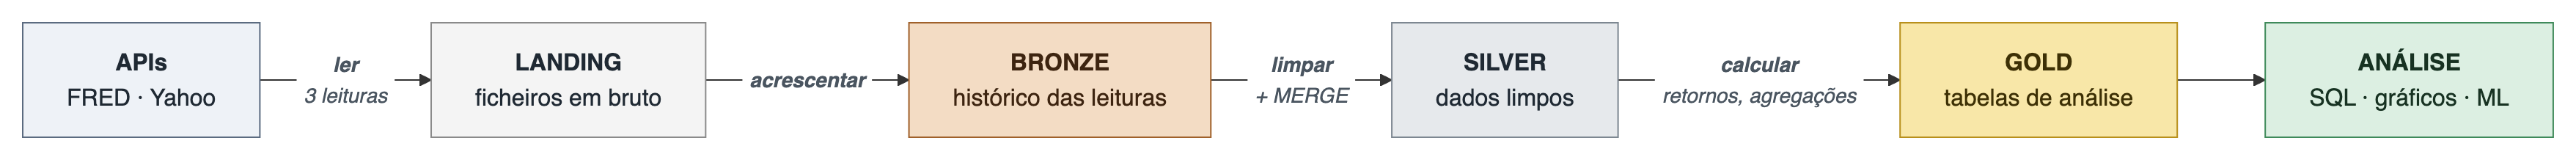

In [1]:
# Diagrama da arquitetura Medallion (fonte Mermaid: img/arquitetura_medallion.mmd)
import os
from IPython.display import Image, display as mostrar_imagem   # outro nome: não substituir o display do Databricks
_diagrama = "img/arquitetura_medallion.png"
if os.path.exists(_diagrama):
    mostrar_imagem(Image(filename=_diagrama))
else:
    print("Diagrama não encontrado (notebook importado sem a Git folder): ver img/arquitetura_medallion.png no repositório.")

### Empresas analisadas e hipótese

**Razão da hipótese:** para quase todas as empresas o petróleo é um **custo** (energia, transporte, poder de compra dos clientes); para a Galp é **receita**.

Cada empresa tem dois sinais esperados. O primeiro é o da hipótese, que é o que testamos: a Galp sobe quando o Brent sobe e as outras 14 empresas descem. É este sentido que decide o veredicto. O segundo é a leitura por setor, uma expectativa mais fina, por grupo, que só serve para interpretar os resultados. "Ambíguo" quer dizer que há forças em sentidos opostos.

#### A exceção: Galp

| Empresa | Expectativa | Porquê |
|---|---|---|
| Galp Energia (`GALP.LS`) | Sobe com o Brent | É uma petrolífera: o petróleo mais caro aumenta as receitas. |

#### As outras 14 empresas, por setor (hipótese: descem quando o Brent sobe)

| Grupo | Empresas | Expectativa | Porquê |
|---|---|---|---|
| Consumo e retalho | Jerónimo Martins (`JMT.LS`), Sonae (`SON.LS`), Ibersol (`IBS.LS`) | Desce com o Brent | O combustível mais caro reduz o poder de compra das famílias, que gastam menos. |
| Serviços domésticos | NOS (`NOS.LS`), CTT (`CTT.LS`) | Desce com o Brent | Dependem da procura interna e têm custos de energia (NOS) e de transporte (CTT). |
| Eletricidade e redes | EDP (`EDP.LS`), EDP Renováveis (`EDPR.LS`), REN (`RENE.LS`) | Ambíguo | O preço da eletricidade acompanha o gás, que acompanha o petróleo, o que pode ajudar a EDP e a EDPR. A REN é um negócio regulado, pouco exposto. |
| Indústria exportadora | Navigator (`NVG.LS`), Altri (`ALTR.LS`), Semapa (`SEM.LS`, dona da Navigator e da Secil), Corticeira Amorim (`COR.LS`) | Ambíguo | Gastam muita energia e transporte (contra), mas vendem em dólares e acompanham o ciclo das matérias-primas (a favor). |
| Exposição a países petrolíferos | Mota-Engil (`EGL.LS`), BCP (`BCP.LS`) | Sobe com o Brent | Têm negócio em Angola e Moçambique (e a Mota-Engil na América Latina), economias que ganham com o petróleo caro. |

As correlações e os betas usam retornos mensais (variações), nunca níveis de preço, porque duas séries que sobem durante 20 anos parecem correlacionadas mesmo sem relação.

Analisamos só as 15 empresas que estão hoje no PSI. As que saíram da bolsa (ex.: PT, BES, Cimpor, Brisa) não entram, o que é um enviesamento de sobrevivência (ver as limitações em 7.2).

<a id="s0"></a>
## 0. Configuração do ambiente

Prepara o ambiente para o notebook correr de cima a baixo (*Run all*), no Databricks ou localmente. Deteta onde está a correr, cria o schema e o Volume e define o catálogo das 22 séries.

In [2]:
import os, json, datetime as dt, uuid, math
import requests
from pyspark.sql import functions as F
from pyspark.sql import Window
from pyspark.sql import types as T

# Deteção do ambiente: no Databricks usamos Delta Lake + Unity Catalog.
# (O notebook também corre em Google Colab / Spark local, guardando as tabelas em Parquet.)
IS_DATABRICKS = "DATABRICKS_RUNTIME_VERSION" in os.environ

if not IS_DATABRICKS:
    import sys, glob, subprocess
    # Os workers do Spark usam o mesmo Python do kernel (evita erros em Windows com vários Pythons instalados)
    os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
    os.environ.setdefault("PYSPARK_DRIVER_PYTHON", sys.executable)

    # O Spark precisa de Java 17 ou 21: se o JAVA_HOME não estiver definido, procuramos um JDK nos sítios habituais (macOS e Windows)
    if not os.environ.get("JAVA_HOME"):
        candidatos = []
        if sys.platform == "darwin":
            for v in ("17", "21"):
                r = subprocess.run(["/usr/libexec/java_home", "-v", v], capture_output=True, text=True)
                if r.returncode == 0:
                    candidatos.append(r.stdout.strip())
            for prefixo in ("/opt/homebrew/opt", "/usr/local/opt"):
                for v in ("17", "21"):
                    candidatos.append(f"{prefixo}/openjdk@{v}/libexec/openjdk.jdk/Contents/Home")
        elif os.name == "nt":
            for pasta in (r"C:\Program Files\Eclipse Adoptium", r"C:\Program Files\Java", r"C:\Program Files\Microsoft"):
                for v in ("17", "21"):
                    candidatos += sorted(glob.glob(os.path.join(pasta, f"jdk-{v}*")), reverse=True)
        java_home = next((c for c in candidatos if os.path.isdir(c)), None)
        if java_home:
            os.environ["JAVA_HOME"] = java_home
        else:
            print("AVISO: falta o Java 17/21. Instalar (ver README, 'Execução local') ou definir o JAVA_HOME.")
    print("JAVA_HOME:", os.environ.get("JAVA_HOME"))

    # As tabelas locais (Parquet) ficam dentro da pasta do lakehouse, e não numa pasta spark-warehouse/ solta na raiz
    WAREHOUSE = os.path.abspath(os.path.join("lakehouse_oil_psi", "warehouse"))

    from pyspark.sql import SparkSession
    spark = (SparkSession.builder.appName("oil_psi_lakehouse")
             .config("spark.sql.warehouse.dir", WAREHOUSE)
             .config("spark.driver.memory", "2g")              # evita o aviso do MemoryManager nas escritas Parquet em paralelo
             .config("spark.ui.showConsoleProgress", "false")  # sem barras [Stage N:>] nas saídas das células
             .config("spark.log.level", "ERROR")               # esconde avisos inofensivos (ex.: WindowExec das janelas globais, ver nota na secção 4)
             .getOrCreate())
    def display(df, n=20):
        print(df.limit(n).toPandas().to_string())

    # As células %sql são do Databricks. Localmente, convertemos "%sql" em "%%sql" e corremos com spark.sql + display
    try:
        ip = get_ipython()
        def _sql_magic(line, cell):
            display(spark.sql(cell))
        ip.register_magic_function(_sql_magic, magic_kind="cell", magic_name="sql")
        def _sql_para_magic(lines):
            if lines and lines[0].strip() == "%sql":
                return ["%%sql\n"] + lines[1:]
            return lines
        ip.input_transformers_cleanup[:] = [t for t in ip.input_transformers_cleanup
                                            if getattr(t, "__name__", "") != "_sql_para_magic"] + [_sql_para_magic]
    except NameError:
        pass   # fora do IPython/Jupyter (ex.: script Python): as células %sql não se aplicam

TABLE_FORMAT = "delta" if IS_DATABRICKS else "parquet"

CATALOG, SCHEMA, VOLUME = "workspace", "oil_psi", "lake"
BASE    = f"/Volumes/{CATALOG}/{SCHEMA}/{VOLUME}" if IS_DATABRICKS else os.path.abspath("lakehouse_oil_psi")
LANDING = f"{BASE}/landing"      # camada de aterragem: ficheiros em bruto exatamente como vieram da API
FALLBACK = f"{BASE}/fallback"   # contingência: cópia antiga das APIs, só usada quando a API falha

RESET = True    # True = apagar tudo e reconstruir de raiz (demonstração). Em produção ficaria False.

print("Databricks:", IS_DATABRICKS, "| formato das tabelas:", TABLE_FORMAT)
print("Base do lakehouse:", BASE)

JAVA_HOME: /opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/13 16:34:12 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Setting Spark log level to "ERROR".


Databricks: False | formato das tabelas: parquet
Base do lakehouse: /Users/jprjustino/Desktop/Nova/2nd Semester/Analyzing Big Data/Project/Projecto-ABD/lakehouse_oil_psi


In [3]:
# Criar o schema (base de dados) e o Volume que guarda os ficheiros do lakehouse
if IS_DATABRICKS:
    spark.sql(f"CREATE SCHEMA IF NOT EXISTS {CATALOG}.{SCHEMA} COMMENT 'Lakehouse: petróleo vs PSI'")
    spark.sql(f"CREATE VOLUME IF NOT EXISTS {CATALOG}.{SCHEMA}.{VOLUME} COMMENT 'Ficheiros landing e fallback'")
    spark.sql(f"USE CATALOG {CATALOG}")
    spark.sql(f"USE SCHEMA {SCHEMA}")
else:
    spark.sql(f"CREATE DATABASE IF NOT EXISTS {SCHEMA}")
    spark.sql(f"USE {SCHEMA}")

ALL_TABLES = ["ctl_ingestion_log", "bz_fred_observations", "bz_yahoo_chart",
              "sv_dim_instrument", "sv_fact_price_daily", "sv_fact_equity_daily", "sv_fact_pt_shares_monthly", "sv_fact_cpi_monthly",
              "gd_market_daily", "gd_market_monthly", "gd_market_yearly", "gd_equity_monthly", "gd_oil_sensitivity",
              "sv_fact_psi_daily"]   # sv_fact_psi_daily: tabela da versão anterior (o PSI passou para sv_fact_equity_daily)

# Localmente o catálogo é em memória: ao reiniciar o kernel esquece as tabelas, mas os ficheiros Parquet ficam no disco
# e o DROP TABLE não os apaga (o saveAsTable falharia com LOCATION_ALREADY_EXISTS). Por isso o RESET local apaga também as pastas.
import shutil
pasta_tabela = lambda t: os.path.join(WAREHOUSE, f"{SCHEMA}.db", t)
if RESET:
    for t in ALL_TABLES:
        spark.sql(f"DROP TABLE IF EXISTS {t}")
        if not IS_DATABRICKS:
            shutil.rmtree(pasta_tabela(t), ignore_errors=True)
    shutil.rmtree(LANDING, ignore_errors=True)   # o fallback NÃO é apagado
elif not IS_DATABRICKS:
    orfas = [t for t in ALL_TABLES if os.path.isdir(pasta_tabela(t)) and not spark.catalog.tableExists(t)]
    if orfas:
        print("AVISO: com RESET = False, as tabelas de um kernel anterior não existem no catálogo local (é em memória):",
              ", ".join(orfas), "\n        A escrita vai falhar com LOCATION_ALREADY_EXISTS. Localmente, usar RESET = True.")
os.makedirs(LANDING, exist_ok=True)

# Ficheiros de fallback: copiados automaticamente da pasta dados_fallback/ do repositório (localmente ou numa Git folder do Databricks,
# onde a pasta de trabalho é a do notebook). Só copia o que falta ou mudou; se não houver dados_fallback/, o upload é manual.
DADOS_FALLBACK = next((p for p in (os.path.abspath("dados_fallback"), os.path.abspath(os.path.join("..", "dados_fallback")))
                    if os.path.isdir(p)), None)
if DADOS_FALLBACK:
    os.makedirs(FALLBACK, exist_ok=True)
    copiados, existentes = 0, 0
    for f in sorted(os.listdir(DADOS_FALLBACK)):
        origem, destino = os.path.join(DADOS_FALLBACK, f), os.path.join(FALLBACK, f)
        if not os.path.isfile(origem) or f.startswith("."):
            continue
        if os.path.isfile(destino) and os.path.getsize(destino) == os.path.getsize(origem):
            existentes += 1
        else:
            shutil.copyfile(origem, destino)
            copiados += 1
    print(f"Fallback de {DADOS_FALLBACK}: {copiados} copiados, {existentes} já existiam em {FALLBACK}")
else:
    print("Pasta dados_fallback/ não encontrada: os ficheiros de fallback têm de ser carregados à mão para", FALLBACK)

print("Ficheiros de fallback disponíveis:", sorted(os.listdir(FALLBACK)) if os.path.isdir(FALLBACK) else "nenhum (só será possível ler das APIs)")

Fallback de /Users/jprjustino/Desktop/Nova/2nd Semester/Analyzing Big Data/Project/Projecto-ABD/dados_fallback: 0 copiados, 22 já existiam em /Users/jprjustino/Desktop/Nova/2nd Semester/Analyzing Big Data/Project/Projecto-ABD/lakehouse_oil_psi/fallback
Ficheiros de fallback disponíveis: ['fred_CP0000PTM086NEST.csv', 'fred_DCOILBRENTEU.csv', 'fred_DCOILWTICO.csv', 'fred_DEXUSEU.csv', 'fred_SPASTT01PTM661N.csv', 'yahoo_ALTR.LS.json', 'yahoo_BCP.LS.json', 'yahoo_COR.LS.json', 'yahoo_CTT.LS.json', 'yahoo_EDP.LS.json', 'yahoo_EDPR.LS.json', 'yahoo_EGL.LS.json', 'yahoo_GALP.LS.json', 'yahoo_IBS.LS.json', 'yahoo_IDX_STOXX50E.json', 'yahoo_JMT.LS.json', 'yahoo_NOS.LS.json', 'yahoo_NVG.LS.json', 'yahoo_PSI20.LS.json', 'yahoo_RENE.LS.json', 'yahoo_SEM.LS.json', 'yahoo_SON.LS.json']


In [4]:
# Catálogo das séries que alimentam o lakehouse (metadados de negócio)
FRED_SERIES = {
    "DCOILBRENTEU":    {"name": "Brent - preço spot",                         "unit": "USD/barril",   "currency": "USD", "freq": "D", "category": "Petróleo"},
    "DCOILWTICO":      {"name": "WTI - preço spot",                           "unit": "USD/barril",   "currency": "USD", "freq": "D", "category": "Petróleo"},
    "DEXUSEU":         {"name": "Câmbio EUR/USD (USD por 1 EUR)",             "unit": "USD por EUR",  "currency": "USD", "freq": "D", "category": "Câmbio"},
    "SPASTT01PTM661N": {"name": "OCDE - índice de preços de ações Portugal",   "unit": "Índice 2015=100", "currency": "EUR", "freq": "M", "category": "Ações PT"},
    "CP0000PTM086NEST": {"name": "IHPC Portugal - índice harmonizado de preços no consumidor", "unit": "Índice", "currency": "EUR", "freq": "M", "category": "Inflação"},
}

# Empresas: sector = grupo de setor; hypothesis = sinal esperado pela hipótese do grupo (petróleo sobe -> ação desce,
# exceto a Galp); sector_view = sinal esperado pela leitura do setor ('?' = ambíguo)
def _eq(name, sector, hypothesis, sector_view):
    return {"name": name, "unit": "EUR", "currency": "EUR", "freq": "D", "category": "Ações PT",
            "sector": sector, "hypothesis": hypothesis, "sector_view": sector_view}
YAHOO_SYMBOLS = {
    "PSI20.LS":        {"name": "PSI - Euronext Lisbon",                     "unit": "Pontos",       "currency": "EUR", "freq": "D", "category": "Ações PT"},
    # Bolsa europeia (controlo do efeito C na secção 4.1): sem setor, por isso não entra nas empresas
    "^STOXX50E":       {"name": "Euro Stoxx 50",                             "unit": "Pontos",       "currency": "EUR", "freq": "D", "category": "Ações Europa"},
    "GALP.LS": _eq("Galp Energia",      "Petróleo e gás",                  "+", "+"),
    "EDP.LS":  _eq("EDP",               "Eletricidade e redes",            "-", "?"),
    "EDPR.LS": _eq("EDP Renováveis",    "Eletricidade e redes",            "-", "?"),
    "RENE.LS": _eq("REN",               "Eletricidade e redes",            "-", "?"),
    "NVG.LS":  _eq("Navigator",         "Indústria exportadora",           "-", "?"),
    "ALTR.LS": _eq("Altri",             "Indústria exportadora",           "-", "?"),
    "SEM.LS":  _eq("Semapa",            "Indústria exportadora",           "-", "?"),
    "COR.LS":  _eq("Corticeira Amorim", "Indústria exportadora",           "-", "?"),
    "JMT.LS":  _eq("Jerónimo Martins",  "Consumo e retalho",               "-", "-"),
    "SON.LS":  _eq("Sonae",             "Consumo e retalho",               "-", "-"),
    "IBS.LS":  _eq("Ibersol",           "Consumo e retalho",               "-", "-"),
    "NOS.LS":  _eq("NOS",               "Serviços domésticos",             "-", "-"),
    "CTT.LS":  _eq("CTT",               "Serviços domésticos",             "-", "-"),
    "EGL.LS":  _eq("Mota-Engil",        "Exposição a países petrolíferos", "-", "+"),
    "BCP.LS":  _eq("BCP",               "Exposição a países petrolíferos", "-", "+"),
}

<a id="s1"></a>
## 1. Ingestão: Camada LANDING

A Landing é a entrada do lakehouse e guarda em ficheiros a resposta das APIs, tal como chega. Se uma regra mais à frente estiver errada, o original continua guardado e pode ser processado de novo.

Cada leitura (*batch*) pede a cada série uma janela de datas e grava a resposta num ficheiro novo, organizado por fonte, série e data de ingestão. Fica também registada no `ctl_ingestion_log`, com a série, a janela pedida, a origem (API ou *fallback*) e as linhas recebidas.

`landing/<fonte>/<série>/ingest_date=AAAA-MM-DD/<série>_<batch_id>.csv|json`

In [5]:
# O User-Agent depende da fonte (testado em 11-11-2026): o Yahoo recusa o do requests (HTTP 429) e precisa de um tipo "browser";
# o FRED faz o contrário, não responde a User-Agents tipo "browser" (timeout) e responde logo ao do requests.
YAHOO_HEADERS = {"User-Agent": "Mozilla/5.0 (EDSA ABD student project)"}

def _http_get(url, params, headers=None):
    r = requests.get(url, params=params, headers=headers, timeout=30)
    r.raise_for_status()
    return r.text

def _nome_ficheiro(serie):
    # o '^' dos índices do Yahoo (ex.: ^STOXX50E) não pode ir no nome do ficheiro
    return serie.replace("^", "IDX_")

def _to_epoch(d):
    return int(dt.datetime.strptime(d, "%Y-%m-%d").replace(tzinfo=dt.timezone.utc).timestamp())

def fetch_fred(series_id, start, end):
    """Lê uma série do FRED (CSV). Se a API não estiver acessível, usa o ficheiro de fallback com a mesma janela de datas."""
    try:
        txt = _http_get("https://fred.stlouisfed.org/graph/fredgraph.csv",
                        {"id": series_id, "cosd": start, "coed": end})
        if not txt.startswith("observation_date"):
            raise ValueError("resposta inesperada da API")
        return txt, "API"
    except Exception as e:
        lines = open(find_fallback(f"fred_{series_id}.csv"), encoding="utf-8").read().strip().splitlines()
        body = [l for l in lines[1:] if start <= l[:10] <= end]
        return "\n".join([lines[0]] + body) + "\n", f"FALLBACK ({type(e).__name__})"

def fetch_yahoo(symbol, start, end):
    """Lê o histórico diário de um índice do Yahoo Finance (JSON). Contingência: ficheiro de fallback filtrado pela janela."""
    p1, p2 = _to_epoch(start), _to_epoch(end) + 86400
    try:
        txt = _http_get(f"https://query1.finance.yahoo.com/v8/finance/chart/{symbol}",
                        {"period1": p1, "period2": p2, "interval": "1d"}, YAHOO_HEADERS)
        json.loads(txt)["chart"]["result"][0]["timestamp"]
        return txt, "API"
    except Exception as e:
        j = json.load(open(find_fallback(f"yahoo_{_nome_ficheiro(symbol)}.json"), encoding="utf-8"))
        res = j["chart"]["result"][0]
        idx = [i for i, t in enumerate(res["timestamp"]) if p1 <= t < p2]
        res["timestamp"] = [res["timestamp"][i] for i in idx]
        for block in ("quote", "adjclose"):
            for serie in res["indicators"].get(block, []):
                for k in serie:
                    serie[k] = [serie[k][i] for i in idx]
        return json.dumps(j), f"FALLBACK ({type(e).__name__})"

def find_fallback(filename):
    """Procura o ficheiro de fallback na pasta fallback/ e, se não estiver lá, em qualquer pasta do Volume (ignora maiúsculas)."""
    for root, _, files in os.walk(BASE):
        if "/landing" in root:
            continue
        for f in files:
            if f.lower() == filename.lower():
                return os.path.join(root, f)
    raise FileNotFoundError(f"A API está bloqueada e não encontrei '{filename}' no Volume {BASE}. "
                            f"É preciso carregar os ficheiros da pasta dados_fallback para {FALLBACK}/")

def land(source, series, payload, ext, batch_id, ingest_date):
    nome = _nome_ficheiro(series)
    folder = f"{LANDING}/{source}/{nome}/ingest_date={ingest_date}"
    os.makedirs(folder, exist_ok=True)
    path = f"{folder}/{nome}_{batch_id}.{ext}"
    with open(path, "w", encoding="utf-8") as f:
        f.write(payload)
    return path

In [6]:
from concurrent.futures import ThreadPoolExecutor

# Regra única para escolher a janela de cada série, usada pelas duas leituras (secção 1.1 e run_pipeline na secção 5)
HIST_START   = "2000-01-01"
OVERLAP_DAYS = 45
all_series   = list(FRED_SERIES) + list(YAHOO_SYMBOLS)

def watermarks():
    """Última data já guardada na Bronze, por série. Antes da primeira leitura a Bronze não existe: devolve {}."""
    if not spark.catalog.tableExists("bz_fred_observations"):
        return {}
    wf = spark.table("bz_fred_observations").groupBy("series_id").agg(F.max("observation_date").alias("wm"))
    wy = spark.table("bz_yahoo_chart").groupBy("symbol").agg(F.to_date(F.from_unixtime(F.max("ts_epoch"))).cast("string").alias("wm"))
    return {r[0]: r[1] for r in wf.collect() + wy.collect()}

def plan_windows(end_date):
    """Sem dados na Bronze: carga completa desde HIST_START. Com dados: só o que falta, a partir do watermark - OVERLAP_DAYS."""
    wm = watermarks()
    return {s: ((dt.date.fromisoformat(wm[s]) - dt.timedelta(days=OVERLAP_DAYS)).isoformat() if s in wm else HIST_START, end_date)
            for s in all_series}

LOG_SCHEMA = T.StructType([
    T.StructField("batch_id", T.StringType()), T.StructField("batch_name", T.StringType()),
    T.StructField("source", T.StringType()), T.StructField("series_id", T.StringType()),
    T.StructField("window_start", T.StringType()), T.StructField("window_end", T.StringType()),
    T.StructField("extract_mode", T.StringType()), T.StructField("records", T.LongType()),
    T.StructField("landing_file", T.StringType()), T.StructField("ingestion_ts", T.TimestampType()),
])

def ingest(batch_name, windows, ingest_date=None):
    """Executa uma leitura (batch) de todas as séries. windows = {series_id: (start, end)}.
    Devolve o batch_id e a lista de ficheiros gravados na landing."""
    batch_id = dt.datetime.now(dt.timezone.utc).replace(tzinfo=None).strftime("%Y%m%dT%H%M%S") + "_" + uuid.uuid4().hex[:6]
    ingest_date = ingest_date or dt.date.today().isoformat()
    now = dt.datetime.now(dt.timezone.utc).replace(tzinfo=None)

    def read_one(source, sid):
        start, end = windows[sid]
        if source == "FRED":
            txt, mode = fetch_fred(sid, start, end)
            path = land("fred", sid, txt, "csv", batch_id, ingest_date)
            n = max(len(txt.strip().splitlines()) - 1, 0)
        else:
            txt, mode = fetch_yahoo(sid, start, end)
            path = land("yahoo", sid, txt, "json", batch_id, ingest_date)
            n = len(json.loads(txt)["chart"]["result"][0].get("timestamp") or [])
        return (batch_id, batch_name, source, sid, start, end, mode, n, path, now)

    # Os pedidos às APIs são feitos em paralelo (8 de cada vez): o tempo é quase todo espera pela rede, não CPU.
    # Cada série continua com o seu próprio fallback; o map devolve os resultados pela ordem do catálogo.
    pedidos = [("FRED", s) for s in FRED_SERIES] + [("YAHOO", s) for s in YAHOO_SYMBOLS]
    with ThreadPoolExecutor(max_workers=8) as ex:
        log = list(ex.map(lambda p: read_one(*p), pedidos))
    files = [(r[2].lower(), r[8]) for r in log]
    spark.createDataFrame(log, LOG_SCHEMA).write.format(TABLE_FORMAT).mode("append").saveAsTable("ctl_ingestion_log")
    for r in log:
        print(f"  {r[2]:5} {r[3]:16} {r[4]} → {r[5]}  {r[7]:>6} registos  [{r[6]}]")
    return batch_id, files

<a id="s1-1"></a>
### 1.1 Primeira leitura: carga histórica (01-01-2000 a 30-06-2026)
Para simular um processo real, a carga é feita em duas leituras: a carga histórica agora e uma leitura incremental na secção 5, até hoje. Ainda não há dados no lakehouse, por isso esta leitura pede tudo desde 2000. A janela vem de `plan_windows`, a mesma regra da leitura seguinte, e termina em 30-06-2026 para deixar meses novos para a leitura incremental.

In [7]:
# Diagnóstico: listar os ficheiros do Volume (exceto a landing) para confirmar que os ficheiros de fallback estão em fallback/
for root, dirs, files in os.walk(BASE):
    if "/landing" not in root:
        print(root, files)

/Users/jprjustino/Desktop/Nova/2nd Semester/Analyzing Big Data/Project/Projecto-ABD/lakehouse_oil_psi []
/Users/jprjustino/Desktop/Nova/2nd Semester/Analyzing Big Data/Project/Projecto-ABD/lakehouse_oil_psi/fallback ['yahoo_RENE.LS.json', 'yahoo_CTT.LS.json', 'yahoo_NVG.LS.json', 'yahoo_BCP.LS.json', 'yahoo_EDP.LS.json', 'fred_DCOILBRENTEU.csv', 'yahoo_ALTR.LS.json', 'yahoo_NOS.LS.json', 'yahoo_PSI20.LS.json', 'yahoo_IBS.LS.json', 'yahoo_COR.LS.json', 'fred_SPASTT01PTM661N.csv', 'fred_DEXUSEU.csv', 'yahoo_EDPR.LS.json', 'yahoo_EGL.LS.json', 'yahoo_SON.LS.json', 'yahoo_IDX_STOXX50E.json', 'fred_CP0000PTM086NEST.csv', 'yahoo_GALP.LS.json', 'fred_DCOILWTICO.csv', 'yahoo_JMT.LS.json', 'yahoo_SEM.LS.json']
/Users/jprjustino/Desktop/Nova/2nd Semester/Analyzing Big Data/Project/Projecto-ABD/lakehouse_oil_psi/warehouse []
/Users/jprjustino/Desktop/Nova/2nd Semester/Analyzing Big Data/Project/Projecto-ABD/lakehouse_oil_psi/warehouse/oil_psi.db []


In [8]:
HIST_END = "2026-06-30"

# A Bronze ainda está vazia, por isso plan_windows pede tudo desde 2000 (carga completa)
batch1_id, batch1_files = ingest("carga_inicial", plan_windows(HIST_END))

  FRED  DCOILBRENTEU     2000-01-01 → 2026-06-30    6911 registos  [API]
  FRED  DCOILWTICO       2000-01-01 → 2026-06-30    6911 registos  [API]
  FRED  DEXUSEU          2000-01-01 → 2026-06-30    6912 registos  [API]
  FRED  SPASTT01PTM661N  2000-01-01 → 2026-06-30     318 registos  [API]
  FRED  CP0000PTM086NEST 2000-01-01 → 2026-06-30     318 registos  [API]
  YAHOO PSI20.LS         2000-01-01 → 2026-06-30    3369 registos  [API]
  YAHOO ^STOXX50E        2000-01-01 → 2026-06-30    4837 registos  [API]
  YAHOO GALP.LS          2000-01-01 → 2026-06-30    5037 registos  [API]
  YAHOO EDP.LS           2000-01-01 → 2026-06-30    6813 registos  [API]
  YAHOO EDPR.LS          2000-01-01 → 2026-06-30    4626 registos  [API]
  YAHOO RENE.LS          2000-01-01 → 2026-06-30    4856 registos  [API]
  YAHOO NVG.LS           2000-01-01 → 2026-06-30    6813 registos  [API]
  YAHOO ALTR.LS          2000-01-01 → 2026-06-30    6813 registos  [API]
  YAHOO SEM.LS           2000-01-01 → 2026-06-30   

In [9]:
# Verificar os ficheiros em bruto na landing (exatamente como vieram da fonte)
for src, path in batch1_files:
    print(path.replace(BASE, "…"), f"{os.path.getsize(path)/1024:.0f} KB")
print()
print(open(batch1_files[0][1]).read()[:200])

…/landing/fred/DCOILBRENTEU/ingest_date=2026-11-13/DCOILBRENTEU_20261113T163415_9a5090.csv 113 KB
…/landing/fred/DCOILWTICO/ingest_date=2026-11-13/DCOILWTICO_20261113T163415_9a5090.csv 112 KB
…/landing/fred/DEXUSEU/ingest_date=2026-11-13/DEXUSEU_20261113T163415_9a5090.csv 120 KB
…/landing/fred/SPASTT01PTM661N/ingest_date=2026-11-13/SPASTT01PTM661N_20261113T163415_9a5090.csv 6 KB
…/landing/fred/CP0000PTM086NEST/ingest_date=2026-11-13/CP0000PTM086NEST_20261113T163415_9a5090.csv 5 KB
…/landing/yahoo/PSI20.LS/ingest_date=2026-11-13/PSI20.LS_20261113T163415_9a5090.json 321 KB
…/landing/yahoo/IDX_STOXX50E/ingest_date=2026-11-13/IDX_STOXX50E_20261113T163415_9a5090.json 474 KB
…/landing/yahoo/GALP.LS/ingest_date=2026-11-13/GALP.LS_20261113T163415_9a5090.json 548 KB
…/landing/yahoo/EDP.LS/ingest_date=2026-11-13/EDP.LS_20261113T163415_9a5090.json 741 KB
…/landing/yahoo/EDPR.LS/ingest_date=2026-11-13/EDPR.LS_20261113T163415_9a5090.json 493 KB
…/landing/yahoo/RENE.LS/ingest_date=2026-11-13/RENE.LS

A primeira leitura deixou na landing um ficheiro por série, tal como veio da API, e o registo de cada leitura no `ctl_ingestion_log`. A secção seguinte carrega estes ficheiros para tabelas.

<a id="s2"></a>
## 2. Camada BRONZE: histórico de leituras (pronto para reprocessamento)

Na Bronze os dados passam de ficheiros para tabelas. Cada leitura é carregada sem limpar nem deduplicar e junta-se às anteriores (*append-only*), de modo que a Bronze guarda o histórico completo do que a fonte enviou. É a partir dela que a Silver se reconstrói (secção 5.1).

Os valores ficam como vieram, em texto ou número em bruto. Cada linha ganha quatro metadados de linhagem: a leitura (`_batch_id`), o momento (`_ingestion_ts`), o ficheiro de origem (`_source_file`) e a data de ingestão (`_ingest_date`). Há uma tabela por fonte:
- `bz_fred_observations`: uma linha por série, data e leitura;
- `bz_yahoo_chart`: uma linha por símbolo, *timestamp* e leitura, extraída do JSON aninhado da API.

In [10]:
def load_bronze_fred(paths, batch_id):
    dfs = []
    for p in paths:
        series_id = p.split("/fred/")[1].split("/")[0]
        raw = spark.read.option("header", True).csv(p)                    # tudo como string (dados em bruto)
        dfs.append(raw.select(
            F.lit(series_id).alias("series_id"),
            F.col("observation_date").alias("observation_date"),
            F.col(series_id).alias("value_raw"),
            F.lit(batch_id).alias("_batch_id"),
            F.current_timestamp().alias("_ingestion_ts"),
            F.col("_metadata.file_path").alias("_source_file"),
            F.regexp_extract(F.col("_metadata.file_path"), r"ingest_date=([0-9-]+)", 1).alias("_ingest_date"),
        ))
    out = dfs[0]
    for d in dfs[1:]:
        out = out.unionByName(d)
    out.write.format(TABLE_FORMAT).mode("append").partitionBy("_ingest_date").saveAsTable("bz_fred_observations")
    return out.count()

def load_bronze_yahoo(paths, batch_id):
    raw = spark.read.option("multiLine", True).json(paths)
    res = raw.select(F.explode("chart.result").alias("r"), F.col("_metadata.file_path").alias("_source_file"))
    q = "r.indicators.quote"
    # fecho ajustado a dividendos e operações de capital (bloco indicators.adjclose do JSON); se a API não o devolver, fica nulo
    has_adj = "adjclose" in res.schema["r"].dataType["indicators"].dataType.fieldNames()
    adj_col = F.col("r.indicators.adjclose.adjclose")[0][F.col("i")].cast("double") if has_adj else F.lit(None).cast("double")
    out = (res.select("*", F.posexplode("r.timestamp").alias("i", "ts_epoch"))
              .select(
                  F.col("r.meta.symbol").alias("symbol"),
                  F.col("r.meta.currency").alias("currency"),
                  F.col("r.meta.exchangeTimezoneName").alias("exchange_tz"),
                  F.col("ts_epoch").cast("long").alias("ts_epoch"),
                  F.col(f"{q}.open")[0][F.col("i")].alias("open_raw"),
                  F.col(f"{q}.high")[0][F.col("i")].alias("high_raw"),
                  F.col(f"{q}.low")[0][F.col("i")].alias("low_raw"),
                  F.col(f"{q}.close")[0][F.col("i")].alias("close_raw"),
                  F.col(f"{q}.volume")[0][F.col("i")].alias("volume_raw"),
                  adj_col.alias("adjclose_raw"),
                  F.lit(batch_id).alias("_batch_id"),
                  F.current_timestamp().alias("_ingestion_ts"),
                  F.col("_source_file"),
                  F.regexp_extract("_source_file", r"ingest_date=([0-9-]+)", 1).alias("_ingest_date"),
              ))
    out.write.format(TABLE_FORMAT).mode("append").partitionBy("_ingest_date").saveAsTable("bz_yahoo_chart")
    return out.count()

def load_bronze(batch_id, files):
    n1 = load_bronze_fred([p for s, p in files if s == "fred"], batch_id)
    n2 = load_bronze_yahoo([p for s, p in files if s == "yahoo"], batch_id)
    print(f"Bronze ← batch {batch_id}: {n1} linhas FRED, {n2} linhas Yahoo")

load_bronze(batch1_id, batch1_files)

Bronze ← batch 20261113T163415_9a5090: 21370 linhas FRED, 100603 linhas Yahoo


In [11]:
display(spark.table("bz_fred_observations").limit(5))
display(spark.table("bz_yahoo_chart").limit(5))
spark.table("bz_yahoo_chart").printSchema()

      series_id observation_date value_raw               _batch_id              _ingestion_ts                                                                                                                                                                                               _source_file _ingest_date
0  DCOILBRENTEU       2000-01-04     23.95  20261113T163415_9a5090 2026-11-13 16:34:20.633571  file:/Users/jprjustino/Desktop/Nova/2nd%20Semester/Analyzing%20Big%20Data/Project/Projecto-ABD/lakehouse_oil_psi/landing/fred/DCOILBRENTEU/ingest_date=2026-11-13/DCOILBRENTEU_20261113T163415_9a5090.csv   2026-11-13
1  DCOILBRENTEU       2000-01-05     23.72  20261113T163415_9a5090 2026-11-13 16:34:20.633571  file:/Users/jprjustino/Desktop/Nova/2nd%20Semester/Analyzing%20Big%20Data/Project/Projecto-ABD/lakehouse_oil_psi/landing/fred/DCOILBRENTEU/ingest_date=2026-11-13/DCOILBRENTEU_20261113T163415_9a5090.csv   2026-11-13
2  DCOILBRENTEU       2000-01-06     23.55  20261113T163415_9a5090 202

<a id="s2-1"></a>
### 2.1 Qualidade dos dados em bruto
Antes de normalizar, medimos os problemas que existem na fonte: valores em falta (feriados, dias sem cotação), duplicados e tipos de dados (no FRED tudo chega como texto).

In [12]:
bz_f = spark.table("bz_fred_observations")
display(bz_f.groupBy("series_id").agg(
    F.count("*").alias("linhas"),
    F.sum(F.when((F.col("value_raw").isNull()) | (F.trim("value_raw").isin("", ".")), 1).otherwise(0)).alias("valores_em_falta"),
    F.min("observation_date").alias("primeira_data"), F.max("observation_date").alias("ultima_data"),
    (F.count("*") - F.countDistinct("observation_date")).alias("duplicados"),
).orderBy("series_id"))

bz_y = spark.table("bz_yahoo_chart")
display(bz_y.groupBy("symbol").agg(
    F.count("*").alias("linhas"),
    F.sum(F.when(F.col("close_raw").isNull(), 1).otherwise(0)).alias("fecho_em_falta"),
    F.sum(F.when(F.col("adjclose_raw").isNull(), 1).otherwise(0)).alias("ajustado_em_falta"),
    F.sum(F.when(F.col("volume_raw") == 0, 1).otherwise(0)).alias("volume_zero"),
    F.from_unixtime(F.min("ts_epoch")).alias("primeiro"), F.from_unixtime(F.max("ts_epoch")).alias("ultimo"),
).orderBy("symbol"))

          series_id  linhas  valores_em_falta primeira_data ultima_data  duplicados
0  CP0000PTM086NEST     318                 0    2000-01-01  2026-06-01           0
1      DCOILBRENTEU    6911               499    2000-01-04  2026-06-30           0
2        DCOILWTICO    6911               647    2000-01-04  2026-06-30           0
3           DEXUSEU    6912               270    2000-01-03  2026-06-30           0
4   SPASTT01PTM661N     318                 0    2000-01-01  2026-06-01           0


       symbol  linhas  fecho_em_falta  ajustado_em_falta  volume_zero             primeiro               ultimo
0     ALTR.LS    6813               0                  0           86  2000-01-03 09:00:00  2026-06-30 09:00:00
1      BCP.LS    6813               0                  0           84  2000-01-03 09:00:00  2026-06-30 09:00:00
2      COR.LS    6813               0                  0          239  2000-01-03 09:00:00  2026-06-30 09:00:00
3      CTT.LS    3213               0                  0            6  2013-12-05 09:00:00  2026-06-30 09:00:00
4      EDP.LS    6813               0                  0           83  2000-01-03 09:00:00  2026-06-30 09:00:00
5     EDPR.LS    4626               0                  0            6  2008-06-04 09:00:00  2026-06-30 09:00:00
6      EGL.LS    6535               0                  0           60  2001-01-25 09:00:00  2026-06-30 09:00:00
7     GALP.LS    5037               0                  0            8  2006-10-24 09:00:00  2026-06-30 0

A Bronze fica com as duas tabelas e os metadados de linhagem, e os problemas da fonte estão medidos: valores em falta, duplicados e, no FRED, tudo em texto. A Silver trata cada um com uma regra.

<a id="s3"></a>
## 3. Camada SILVER: dados normalizados e modelados para o tema

A Silver corrige os dados. Parte da Bronze, aplica uma regra a cada problema medido em 2.1 e fica com um registo por série e data, com o tipo certo. Os dados ficam organizados para o tema, numa dimensão de instrumentos e em factos diários e mensais.

**Regras de normalização ("data rules")**
1. Tipos: `value_raw` (texto) → `double`; datas em texto → `date`; *timestamps* Unix → data local de Lisboa.
2. Nulos: os valores vazios ou `.` (o "sem observação" do FRED) são eliminados. No PSI, os dias sem fecho também.
3. Duplicados: a mesma (série, data) pode chegar em várias leituras. Fica a leitura mais recente (`_ingestion_ts`), o que também corrige revisões da fonte.
4. Validação: os preços <= 0 ficam marcados com `dq_flag`, sem serem apagados. Exemplo real: o WTI fechou a -36,98 USD em 20-04-2020.
5. Ações: guarda-se o fecho e o fecho ajustado (`adj_close`, a dividendos e operações de capital). Os retornos das empresas usam sempre o fecho ajustado. Os preços têm 4 casas decimais (há ações abaixo de 1 €, como o BCP).

**Modelo Silver**
- `sv_dim_instrument`: um registo por instrumento, com nome, unidade, moeda, frequência, categoria, setor, sinal esperado pela hipótese e fonte;
- `sv_fact_price_daily`: preços diários do petróleo e do câmbio;
- `sv_fact_equity_daily`: cotações diárias do PSI e das 15 empresas (OHLC, volume e fecho ajustado);
- `sv_fact_pt_shares_monthly`: índice mensal da OCDE para as ações portuguesas;
- `sv_fact_cpi_monthly`: IHPC mensal de Portugal (inflação).

A escrita é incremental: o `MERGE` (*upsert*) atualiza pelas chaves de negócio e não cria duplicados.

In [13]:
def upsert(df, table, keys):
    """Upsert incremental: MERGE INTO no Delta Lake (ou substituição equivalente em Parquet fora do Databricks)."""
    if not spark.catalog.tableExists(table):
        df.write.format(TABLE_FORMAT).saveAsTable(table)
        return
    if TABLE_FORMAT == "delta":
        df.createOrReplaceTempView("_src")
        cond = " AND ".join(f"t.{k} = s.{k}" for k in keys)
        spark.sql(f"""MERGE INTO {table} t USING _src s ON {cond}
                      WHEN MATCHED THEN UPDATE SET *
                      WHEN NOT MATCHED THEN INSERT *""")
    else:
        merged = spark.table(table).join(df.select(*keys), keys, "left_anti").unionByName(df).localCheckpoint()
        merged.write.format(TABLE_FORMAT).mode("overwrite").saveAsTable(table)

def latest_per_key(df, keys):
    w = Window.partitionBy(*keys).orderBy(F.col("_ingestion_ts").desc(), F.col("_batch_id").desc())
    return df.withColumn("_rn", F.row_number().over(w)).filter("_rn = 1").drop("_rn")

In [14]:
# Dimensão de instrumentos (dados de referência), com o setor e o sinal esperado pela hipótese do grupo
def _dim_row(k, v, source):
    return (k, v["name"], v["unit"], v["currency"], v["freq"], v["category"],
            v.get("sector"), v.get("hypothesis"), v.get("sector_view"), source)
dim_rows = [_dim_row(k, v, "FRED") for k, v in FRED_SERIES.items()] + \
           [_dim_row(k, v, "Yahoo Finance") for k, v in YAHOO_SYMBOLS.items()]
dim_instrument = spark.createDataFrame(dim_rows, "instrument_id string, name string, unit string, currency string, frequency string, "
                                                 "category string, sector string, oil_hypothesis string, sector_view string, source string")
upsert(dim_instrument, "sv_dim_instrument", ["instrument_id"])
display(spark.table("sv_dim_instrument"))

       instrument_id                                                        name        unit currency frequency      category                           sector oil_hypothesis sector_view         source
0             NOS.LS                                                         NOS         EUR      EUR         D      Ações PT              Serviços domésticos              -           -  Yahoo Finance
1             CTT.LS                                                         CTT         EUR      EUR         D      Ações PT              Serviços domésticos              -           -  Yahoo Finance
2             EGL.LS                                                  Mota-Engil         EUR      EUR         D      Ações PT  Exposição a países petrolíferos              -           +  Yahoo Finance
3             BCP.LS                                                         BCP         EUR      EUR         D      Ações PT  Exposição a países petrolíferos              -           +  Yahoo Fin

In [15]:
def normalize_fred(bz):
    df = (bz.withColumn("value", F.when(F.trim("value_raw").isin("", "."), None).otherwise(F.col("value_raw")).cast("double"))
            .withColumn("date", F.to_date("observation_date", "yyyy-MM-dd"))
            .filter(F.col("value").isNotNull() & F.col("date").isNotNull()))
    df = latest_per_key(df, ["series_id", "date"])
    return df.select(
        F.col("series_id").alias("instrument_id"), "date", "value",
        F.when(F.col("value") <= 0, "PRECO_NAO_POSITIVO").alias("dq_flag"),
        "_batch_id", F.col("_ingestion_ts").alias("_source_ingestion_ts"), F.current_timestamp().alias("_updated_ts"))

def normalize_yahoo(bz):
    df = (bz.withColumn("date", F.to_date(F.from_utc_timestamp(F.timestamp_seconds("ts_epoch"), "Europe/Lisbon")))
            .filter(F.col("close_raw").isNotNull()))
    df = latest_per_key(df, ["symbol", "date"])
    return df.select(
        F.col("symbol").alias("instrument_id"), "date",
        F.round(F.col("open_raw").cast("double"), 4).alias("open"),
        F.round(F.col("high_raw").cast("double"), 4).alias("high"),
        F.round(F.col("low_raw").cast("double"), 4).alias("low"),
        F.round(F.col("close_raw").cast("double"), 4).alias("close"),
        # fecho ajustado a dividendos e operações de capital; se faltar, usa-se o fecho simples
        F.round(F.coalesce(F.col("adjclose_raw"), F.col("close_raw")).cast("double"), 6).alias("adj_close"),
        F.col("volume_raw").cast("long").alias("volume"),
        F.when(F.col("close_raw") <= 0, "PRECO_NAO_POSITIVO")
         .when(F.col("high_raw") < F.col("low_raw"), "MAX_MENOR_QUE_MIN").alias("dq_flag"),
        "_batch_id", F.col("_ingestion_ts").alias("_source_ingestion_ts"), F.current_timestamp().alias("_updated_ts"))

SILVER_FACTS = ["sv_fact_price_daily", "sv_fact_equity_daily", "sv_fact_pt_shares_monthly", "sv_fact_cpi_monthly"]

def build_silver(batch_id=None):
    """Normaliza a Bronze e faz MERGE na Silver. batch_id=None: reprocessa TODO o histórico da Bronze."""
    bz_f = spark.table("bz_fred_observations")
    bz_y = spark.table("bz_yahoo_chart")
    if batch_id:
        bz_f, bz_y = bz_f.filter(F.col("_batch_id") == batch_id), bz_y.filter(F.col("_batch_id") == batch_id)
    fred = normalize_fred(bz_f)
    daily_ids  = [k for k, v in FRED_SERIES.items() if v["freq"] == "D"]
    shares_ids = [k for k, v in FRED_SERIES.items() if v["freq"] == "M" and v["category"] == "Ações PT"]
    cpi_ids    = [k for k, v in FRED_SERIES.items() if v["freq"] == "M" and v["category"] == "Inflação"]
    upsert(fred.filter(F.col("instrument_id").isin(daily_ids)), "sv_fact_price_daily", ["instrument_id", "date"])
    upsert(fred.filter(F.col("instrument_id").isin(shares_ids)).withColumnRenamed("date", "month_date"),
           "sv_fact_pt_shares_monthly", ["instrument_id", "month_date"])
    upsert(fred.filter(F.col("instrument_id").isin(cpi_ids)).withColumnRenamed("date", "month_date"),
           "sv_fact_cpi_monthly", ["instrument_id", "month_date"])
    upsert(normalize_yahoo(bz_y), "sv_fact_equity_daily", ["instrument_id", "date"])   # PSI + 15 empresas
    for t in SILVER_FACTS:
        print(f"{t:28} {spark.table(t).count():>7} linhas")

build_silver(batch1_id)

sv_fact_price_daily            19318 linhas
sv_fact_equity_daily          100574 linhas
sv_fact_pt_shares_monthly        318 linhas
sv_fact_cpi_monthly              318 linhas


In [16]:
display(spark.table("sv_fact_price_daily").groupBy("instrument_id").agg(
    F.count("*").alias("dias"), F.min("date").alias("de"), F.max("date").alias("ate"),
    F.round(F.min("value"), 2).alias("min"), F.round(F.max("value"), 2).alias("max"),
    F.sum(F.when(F.col("dq_flag").isNotNull(), 1).otherwise(0)).alias("alertas_qualidade")))
display(spark.table("sv_fact_price_daily").filter("dq_flag IS NOT NULL"))
display(spark.table("sv_fact_equity_daily").groupBy("instrument_id").agg(
    F.count("*").alias("dias"), F.min("date").alias("de"), F.max("date").alias("ate"),
    F.round(F.min("adj_close"), 4).alias("min_ajustado"), F.round(F.max("adj_close"), 4).alias("max_ajustado"),
    F.sum(F.when(F.col("dq_flag").isNotNull(), 1).otherwise(0)).alias("alertas_qualidade")).orderBy("instrument_id"))

  instrument_id  dias          de         ate    min     max  alertas_qualidade
0       DEXUSEU  6642  2000-01-03  2026-06-30   0.83    1.60                  0
1    DCOILWTICO  6264  2000-01-04  2026-06-30 -36.98  145.31                  1
2  DCOILBRENTEU  6412  2000-01-04  2026-06-30   9.12  143.95                  0
  instrument_id        date  value             dq_flag               _batch_id       _source_ingestion_ts                _updated_ts
0    DCOILWTICO  2020-04-20 -36.98  PRECO_NAO_POSITIVO  20261113T163415_9a5090 2026-11-13 16:34:20.633571 2026-11-13 16:34:25.138519
   instrument_id  dias          de         ate  min_ajustado  max_ajustado  alertas_qualidade
0        ALTR.LS  6813  2000-01-03  2026-06-30        0.0468        5.9613                  0
1         BCP.LS  6813  2000-01-03  2026-06-30        0.0607       16.3530                  0
2         COR.LS  6813  2000-01-03  2026-06-30        0.2669       10.5878                  0
3         CTT.LS  3213  2013-12-05  20

Cada série tem agora um registo por data, com o tipo certo, e os preços <= 0, como o WTI de 20-04-2020, ficam marcados com `dq_flag` em vez de apagados. A Silver tem uma linha por instrumento e data; a Gold junta tudo numa tabela por data.

<a id="s4"></a>
## 4. Camada GOLD: dados preparados e otimizados para análise

A Gold é a camada que as análises leem. Recebe a Silver e entrega tabelas largas, com as séries num calendário comum, o petróleo em euros e os indicadores já calculados. As queries e os gráficos da secção 6 não precisam de *joins* nem de cálculos à hora da consulta.

**Preparação**
- Calendário único: a união dos dias úteis com cotação em qualquer série.
- *Forward-fill* dos preços nos feriados de um só mercado (ex.: o Brent nos feriados do Reino Unido, o PSI nos portugueses). Os indicadores `*_quoted` dizem se o valor foi observado.
- Brent em euros = Brent em USD a dividir pela taxa EUR/USD. O PSI está em euros, por isso é esta a comparação justa.
- Inflação: o IHPC de Portugal dá o Brent em euros a preços de hoje (`brent_eur_real`), usado nos gráficos de evolução. As correlações usam retornos nominais, porque a inflação mensal (~0,2%) afeta as duas séries por igual.
- Indicadores: retornos logarítmicos, médias móveis de 50 e 200 dias, correlação móvel de 1 ano (252 dias úteis), máximos e *drawdowns*.

**Otimização**
- Tabelas largas (*denormalizadas*).
- `gd_market_daily` particionada por ano, com `OPTIMIZE ... ZORDER BY (date)`: compacta os ficheiros pequenos e permite *data skipping*.
- Agregados pré-calculados: `gd_market_monthly` (2000-2026) e `gd_market_yearly`.
- Tabelas das empresas (secção 4.1): `gd_equity_monthly` e `gd_oil_sensitivity`.

In [17]:
def build_gold():
    px = spark.table("sv_fact_price_daily").groupBy("date").pivot("instrument_id", ["DCOILBRENTEU", "DCOILWTICO", "DEXUSEU"]).agg(F.first("value"))
    px = px.withColumnRenamed("DCOILBRENTEU", "brent_usd_obs").withColumnRenamed("DCOILWTICO", "wti_usd_obs").withColumnRenamed("DEXUSEU", "eurusd_obs")
    psi = (spark.table("sv_fact_equity_daily").filter(F.col("instrument_id") == "PSI20.LS")
              .select("date", F.col("close").alias("psi_close_obs"), F.col("volume").alias("psi_volume")))
    spine = px.select("date").union(psi.select("date")).distinct().filter(F.dayofweek("date").between(2, 6))
    d = spine.join(px, "date", "left").join(psi, "date", "left")

    w_ff = Window.orderBy("date").rowsBetween(Window.unboundedPreceding, 0)    # série única e pequena: janela global
    for c in ["brent_usd", "wti_usd", "eurusd", "psi_close"]:
        d = d.withColumn(c, F.last(f"{c}_obs", ignorenulls=True).over(w_ff))
    d = (d.withColumn("brent_quoted", F.col("brent_usd_obs").isNotNull())
          .withColumn("psi_traded", F.col("psi_close_obs").isNotNull())
          .drop("brent_usd_obs", "wti_usd_obs", "eurusd_obs", "psi_close_obs")
          .withColumn("brent_eur", F.round(F.col("brent_usd") / F.col("eurusd"), 4)))

    w = Window.orderBy("date")
    for c, r in [("brent_usd", "ret_brent_usd"), ("brent_eur", "ret_brent_eur"), ("eurusd", "ret_eurusd"), ("psi_close", "ret_psi")]:
        d = d.withColumn(r, F.log(F.col(c) / F.lag(c).over(w)))
    w50, w200, w252 = [Window.orderBy("date").rowsBetween(-(n - 1), 0) for n in (50, 200, 252)]
    w_all = Window.orderBy("date").rowsBetween(Window.unboundedPreceding, 0)
    d = (d.withColumn("brent_eur_ma50", F.avg("brent_eur").over(w50))
          .withColumn("brent_eur_ma200", F.avg("brent_eur").over(w200))
          .withColumn("psi_ma50", F.avg("psi_close").over(w50))
          .withColumn("psi_ma200", F.avg("psi_close").over(w200))
          .withColumn("corr_1y_psi_brent", F.when(F.count("ret_psi").over(w252) >= 200, F.corr("ret_psi", "ret_brent_eur").over(w252)))
          .withColumn("vol_1y_psi", F.stddev("ret_psi").over(w252) * math.sqrt(252))
          .withColumn("vol_1y_brent", F.stddev("ret_brent_eur").over(w252) * math.sqrt(252))
          .withColumn("psi_drawdown", F.col("psi_close") / F.max("psi_close").over(w_all) - 1)
          .withColumn("brent_eur_drawdown", F.col("brent_eur") / F.max("brent_eur").over(w_all) - 1)
          .withColumn("year", F.year("date")).withColumn("quarter", F.quarter("date")).withColumn("month", F.month("date")))
    (d.write.format(TABLE_FORMAT).mode("overwrite").option("overwriteSchema", "true")
       .partitionBy("year").saveAsTable("gd_market_daily"))

    # Mensal (2000+): petróleo + índice OCDE de ações PT + PSI (desde 2013)
    daily = spark.table("gd_market_daily")
    m = (daily.withColumn("month_date", F.trunc("date", "month")).groupBy("month_date").agg(
            F.round(F.avg("brent_usd"), 2).alias("brent_usd_avg"),
            F.round(F.avg("brent_eur"), 2).alias("brent_eur_avg"),
            F.round(F.avg("wti_usd"), 2).alias("wti_usd_avg"),
            F.round(F.avg("eurusd"), 4).alias("eurusd_avg"),
            F.round(F.max_by("brent_eur", "date"), 2).alias("brent_eur_eom"),
            F.round(F.max_by("psi_close", "date"), 2).alias("psi_eom"),
            F.round(F.avg("psi_close"), 2).alias("psi_avg")))
    oecd = spark.table("sv_fact_pt_shares_monthly").select("month_date", F.round("value", 2).alias("pt_shares_idx"))
    wm = Window.orderBy("month_date")
    m = (m.join(oecd, "month_date", "left")
          # retornos logarítmicos: Brent e PSI no fim do mês; o índice OCDE só existe como média mensal
          .withColumn("ret_brent_eur_m", F.log(F.col("brent_eur_eom") / F.lag("brent_eur_eom").over(wm)))
          .withColumn("ret_pt_shares_m", F.log(F.col("pt_shares_idx") / F.lag("pt_shares_idx").over(wm)))
          .withColumn("ret_psi_m", F.log(F.col("psi_eom") / F.lag("psi_eom").over(wm)))
          .withColumn("yoy_brent_eur", F.col("brent_eur_avg") / F.lag("brent_eur_avg", 12).over(wm) - 1)
          .withColumn("yoy_pt_shares", F.col("pt_shares_idx") / F.lag("pt_shares_idx", 12).over(wm) - 1)
          .withColumn("year", F.year("month_date")))
    # Inflação: IHPC de Portugal, para ter o Brent em euros a preços do último mês publicado (para os gráficos de evolução)
    cpi = spark.table("sv_fact_cpi_monthly").select("month_date", F.col("value").alias("hicp_publicado"))
    w_ffm  = Window.orderBy("month_date").rowsBetween(Window.unboundedPreceding, 0)
    w_allm = Window.orderBy("month_date").rowsBetween(Window.unboundedPreceding, Window.unboundedFollowing)
    m = (m.join(cpi, "month_date", "left")
          .withColumn("hicp", F.last("hicp_publicado", ignorenulls=True).over(w_ffm))     # meses ainda sem IHPC: último valor
          .withColumn("deflator", F.last("hicp", ignorenulls=True).over(w_allm) / F.col("hicp"))
          .withColumn("brent_eur_real", F.round(F.col("brent_eur_avg") * F.col("deflator"), 2)))
    m.write.format(TABLE_FORMAT).mode("overwrite").option("overwriteSchema", "true").saveAsTable("gd_market_monthly")

    # Anual
    # variação anual = valor no fim do ano / valor no fim do ano anterior - 1
    wy = Window.orderBy("year")
    y = (daily.groupBy("year").agg(
            F.round(F.avg("brent_usd"), 2).alias("brent_usd_avg"),
            F.round(F.min("brent_usd"), 2).alias("brent_usd_min"),
            F.round(F.max("brent_usd"), 2).alias("brent_usd_max"),
            F.round(F.avg("brent_eur"), 2).alias("brent_eur_avg"),
            F.round(F.avg("eurusd"), 4).alias("eurusd_avg"),
            F.max_by("brent_eur", "date").alias("brent_eur_eoy"),
            F.max_by("psi_close", "date").alias("psi_eoy"),
            F.round(F.stddev("ret_brent_eur") * math.sqrt(252), 4).alias("vol_brent_eur"),
            F.round(F.stddev("ret_psi") * math.sqrt(252), 4).alias("vol_psi"),
            F.round(F.corr("ret_psi", "ret_brent_eur"), 3).alias("corr_diaria_psi_brent"),
            F.sum(F.col("psi_traded").cast("int")).alias("dias_psi"))
         .join(spark.table("sv_fact_pt_shares_monthly").groupBy(F.year("month_date").alias("year"))
                    .agg(F.max_by("value", "month_date").alias("pt_shares_eoy")), "year", "left")
         .join(spark.table("gd_market_monthly").groupBy("year")
                    .agg(F.round(F.avg("brent_eur_real"), 2).alias("brent_eur_real_avg")), "year", "left")
         .withColumn("var_brent_eur", F.round(F.col("brent_eur_eoy") / F.lag("brent_eur_eoy").over(wy) - 1, 4))
         .withColumn("var_psi", F.round(F.col("psi_eoy") / F.lag("psi_eoy").over(wy) - 1, 4))
         .withColumn("var_pt_shares_oecd", F.round(F.col("pt_shares_eoy") / F.lag("pt_shares_eoy").over(wy) - 1, 4)))
    y.write.format(TABLE_FORMAT).mode("overwrite").option("overwriteSchema", "true").saveAsTable("gd_market_yearly")

    if TABLE_FORMAT == "delta":
        spark.sql("OPTIMIZE gd_market_daily ZORDER BY (date)")
    for t in ["gd_market_daily", "gd_market_monthly", "gd_market_yearly"]:
        print(f"{t:20} {spark.table(t).count():>6} linhas")

build_gold()

gd_market_daily        6822 linhas
gd_market_monthly       318 linhas
gd_market_yearly         27 linhas


In [18]:
display(spark.table("gd_market_daily").orderBy(F.desc("date")).limit(5))

         date  psi_volume  brent_usd  wti_usd  eurusd  psi_close  brent_quoted  psi_traded  brent_eur  ret_brent_usd  ret_brent_eur  ret_eurusd   ret_psi  brent_eur_ma50  brent_eur_ma200     psi_ma50    psi_ma200  corr_1y_psi_brent  vol_1y_psi  vol_1y_brent  psi_drawdown  brent_eur_drawdown  quarter  month  year
0  2026-06-30    67056200      70.46    70.56  1.1417  9132.5898          True        True    61.7150      -0.015910      -0.015209   -0.000700 -0.002941       85.304808        70.566307  9112.815114  8715.202880          -0.093567    0.129793      0.539001     -0.037147           -0.498554        2      6  2026
1  2026-06-29    50113100      71.59    71.87  1.1425  9159.4902          True        True    62.6608       0.020177       0.018249    0.001927  0.002548       85.876838        70.542979  9112.890114  8708.060380          -0.094998    0.129925      0.538834     -0.034311           -0.490869        2      6  2026
2  2026-06-26    51850200      70.16    70.30  1.1403  913

**Nota sobre as janelas sem `PARTITION BY`.** Os indicadores da Gold (*forward-fill*, retornos, médias móveis, correlação e volatilidade de 1 ano, *drawdown*, variações mensais e anuais) calculam-se sobre uma única série ordenada no tempo, com `Window.orderBy("date")` e sem `partitionBy`. Particionar por ano cortaria os desfasamentos (`lag`) e as médias móveis na passagem de ano, e a correlação PSI-Brent precisa das duas séries na mesma linha.

O Spark avisa (`WindowExec: No Partition Defined...`) que assim junta os dados numa só partição, o que com ~7 mil dias não pesa. Com muitas séries particionávamos por série, como na deduplicação da Silver (`latest_per_key`) e na secção 4.1 (`partitionBy("instrument_id")`). Isto não tem a ver com o particionamento em disco da `gd_market_daily` por ano, que serve para o *data skipping*.

<a id="s4-1"></a>
### 4.1 Gold das empresas: retornos mensais e sensibilidade ao petróleo

A hipótese é sobre empresas, por isso a Gold tem duas tabelas só para elas, com dados mensais. A primeira guarda o retorno de cada empresa em cada mês. A segunda mede o efeito do petróleo em cada empresa e dá o veredicto.

**`gd_equity_monthly`**: uma linha por empresa e por mês, com:
- o retorno mensal logarítmico, calculado com o fecho ajustado do último dia de negociação do mês;
- a marca `ret_outlier` nos meses com um dia de variação > 40% no fecho ajustado (provável operação de capital mal ajustada na fonte; ex.: Altri em 2000 e 2005). Esses meses ficam fora das estatísticas;
- o retorno mensal do Brent em EUR e os dos 1, 2 e 3 meses anteriores;
- o mercado PT: a média, com pesos iguais, das outras empresas nesse mês;
- o cabaz `PT_EX_GALP`: a média das 14 empresas sem a Galp;
- a correlação móvel de 36 meses com o Brent e o preço em euros de hoje.

**`gd_oil_sensitivity`**: uma linha por empresa e período (total 2000-2026 e 4 subperíodos), com:
- a correlação mensal e o **beta** (`ret_ação ~ ret_brent_eur`): o efeito total do petróleo;
- o **beta sem mercado** (`ret_ação ~ ret_brent_eur + ret_mercado_pt`): o efeito do petróleo depois de descontar o movimento geral da bolsa. Separa o custo do petróleo do ciclo económico, que move o petróleo e as ações ao mesmo tempo;
- a estatística t (significativo se |t| >= 2) e o veredicto: *Confirma* (sentido esperado e significativo), *Contraria* (significativo no sentido oposto) ou *Sem efeito significativo*;
- as correlações com o petróleo de 1, 2 e 3 meses antes, porque o efeito pode demorar a aparecer.

As regressões são calculadas com agregações do Spark (variâncias e covariâncias por grupo), sem ciclos em Python.

In [19]:
OUTLIER_DAILY = 0.40      # variação diária acima de 40%: provável operação de capital não ajustada na fonte
MIN_MONTHS    = 24        # mínimo de meses para calcular estatísticas
PERIODS = [("Total 2000-2026", 2000, 2026), ("2000-2007", 2000, 2007), ("2008-2013", 2008, 2013),
           ("2014-2019", 2014, 2019), ("2020-2026", 2020, 2026)]
BASKET_ID = "PT_EX_GALP"
EUROPA_ID = "^STOXX50E"    # Euro Stoxx 50: controlo do efeito C (sem a bolsa europeia)

def _verdict(beta, t, n="n_meses"):
    """Confirma = sinal esperado e |t| >= 2; Contraria = |t| >= 2 com o sinal oposto. n: coluna com o nº de meses da regressão."""
    expected = F.when(F.col("oil_hypothesis") == "+", 1).otherwise(-1)
    return (F.when(F.col(n) < MIN_MONTHS, "Dados insuficientes")
             .when(t.isNull(), None)
             .when(F.abs(t) < 2, "Sem efeito significativo")
             .when(F.signum(beta) == expected, "Confirma")
             .otherwise("Contraria"))

def build_gold_equity():
    dim = (spark.table("sv_dim_instrument").filter(F.col("sector").isNotNull())
                .select("instrument_id", "name", "sector", "oil_hypothesis", "sector_view"))
    eq = spark.table("sv_fact_equity_daily").join(dim.select("instrument_id"), "instrument_id")   # só empresas (sem o PSI)

    # Mensal por empresa: fecho ajustado no último dia de negociação + deteção de saltos diários anómalos
    wd = Window.partitionBy("instrument_id").orderBy("date")
    eq = (eq.withColumn("ret_d", F.col("adj_close") / F.lag("adj_close").over(wd) - 1)
            .withColumn("month_date", F.trunc("date", "month")))
    em = eq.groupBy("instrument_id", "month_date").agg(
        F.max_by("adj_close", "date").alias("adj_close_eom"),
        F.max_by("close", "date").alias("close_eom"),
        F.count("*").alias("dias_negociacao"),
        (F.coalesce(F.max((F.abs("ret_d") > OUTLIER_DAILY).cast("int")), F.lit(0)) == 1).alias("ret_outlier"))
    wm = Window.partitionBy("instrument_id").orderBy("month_date")
    em = (em.withColumn("ret_m", F.when(F.months_between("month_date", F.lag("month_date").over(wm)) == 1,
                                        F.log(F.col("adj_close_eom") / F.lag("adj_close_eom").over(wm))))
            .withColumn("ret_m_stat", F.when(~F.col("ret_outlier"), F.col("ret_m"))))     # retorno usado nas estatísticas

    # Mercado PT: média (pesos iguais) das OUTRAS empresas nesse mês
    mk = em.groupBy("month_date").agg(F.sum("ret_m_stat").alias("_soma"), F.count("ret_m_stat").alias("_n"))
    em = (em.join(mk, "month_date", "left")
            .withColumn("ret_mercado_pt",
                        F.when(F.col("ret_m_stat").isNotNull() & (F.col("_n") > 1),
                               (F.col("_soma") - F.col("ret_m_stat")) / (F.col("_n") - 1))
                         .when(F.col("ret_m_stat").isNull() & (F.col("_n") > 0), F.col("_soma") / F.col("_n")))
            .drop("_soma", "_n"))

    # Cabaz das 14 empresas sem a Galp (tratado como mais um "instrumento")
    basket = (em.filter((F.col("instrument_id") != "GALP.LS") & F.col("ret_m_stat").isNotNull())
                .groupBy("month_date").agg(F.avg("ret_m_stat").alias("ret_m"))
                .withColumn("ret_m_stat", F.col("ret_m"))
                .withColumn("ret_outlier", F.lit(False))
                .withColumn("instrument_id", F.lit(BASKET_ID)))
    em = em.unionByName(basket, allowMissingColumns=True)
    dim_all = dim.unionByName(spark.createDataFrame(
        [(BASKET_ID, "Cabaz 14 empresas (sem Galp)", "Cabaz sem Galp", "-", "-")], dim.schema))

    # Brent em EUR no fim do mês, retorno mensal e desfasamentos
    wb = Window.orderBy("month_date")
    brent = (spark.table("gd_market_daily").withColumn("month_date", F.trunc("date", "month"))
               .groupBy("month_date").agg(F.max_by("brent_eur", "date").alias("brent_eur_eom"))
               .withColumn("ret_brent_eur_m", F.log(F.col("brent_eur_eom") / F.lag("brent_eur_eom").over(wb))))
    for k in (1, 2, 3):
        brent = brent.withColumn(f"ret_brent_eur_m_lag{k}", F.lag("ret_brent_eur_m", k).over(wb))
    # Bolsa europeia: retorno logarítmico de fim de mês do Euro Stoxx 50 (existe desde 2007-03)
    europa = (spark.table("sv_fact_equity_daily").filter(F.col("instrument_id") == EUROPA_ID)
                .withColumn("month_date", F.trunc("date", "month")).groupBy("month_date")
                .agg(F.max_by("close", "date").alias("_eu_eom"))
                .withColumn("ret_europa_m", F.log(F.col("_eu_eom") / F.lag("_eu_eom").over(wb))).drop("_eu_eom"))
    defl = spark.table("gd_market_monthly").select("month_date", "deflator")

    w36 = Window.partitionBy("instrument_id").orderBy("month_date").rowsBetween(-35, 0)
    g = (em.join(dim_all, "instrument_id").join(brent, "month_date", "left").join(europa, "month_date", "left")
           .join(defl, "month_date", "left")
           .withColumn("adj_close_real", F.round(F.col("adj_close_eom") * F.col("deflator"), 4))
           .withColumn("_ok", (F.col("ret_m_stat").isNotNull() & F.col("ret_brent_eur_m").isNotNull()).cast("int"))
           .withColumn("corr_36m_brent", F.when(F.sum("_ok").over(w36) >= 30,
                                                 F.corr("ret_m_stat", "ret_brent_eur_m").over(w36)))
           .withColumn("year", F.year("month_date"))
           .select("instrument_id", "name", "sector", "oil_hypothesis", "sector_view", "month_date", "year",
                   "dias_negociacao", "close_eom", "adj_close_eom", "adj_close_real", "ret_m", "ret_outlier", "ret_m_stat",
                   "ret_mercado_pt", "brent_eur_eom", "ret_brent_eur_m", "ret_brent_eur_m_lag1", "ret_brent_eur_m_lag2",
                   "ret_brent_eur_m_lag3", "ret_europa_m", "corr_36m_brent"))
    g.write.format(TABLE_FORMAT).mode("overwrite").option("overwriteSchema", "true").saveAsTable("gd_equity_monthly")

    # Sensibilidade ao petróleo por empresa e período (regressões com agregações do Spark)
    gm = spark.table("gd_equity_monthly").filter(F.col("ret_m_stat").isNotNull() & F.col("ret_brent_eur_m").isNotNull())
    per = spark.createDataFrame(PERIODS, "periodo string, ano_ini int, ano_fim int")
    s = gm.join(F.broadcast(per), (gm.year >= per.ano_ini) & (gm.year <= per.ano_fim))   # cada mês entra no total e no seu subperíodo
    y, x, mk = "ret_m_stat", "ret_brent_eur_m", "ret_mercado_pt"
    agg = s.groupBy("instrument_id", "name", "sector", "oil_hypothesis", "sector_view", "periodo", "ano_ini", "ano_fim").agg(
        F.count("*").alias("n_meses"),
        F.corr(y, x).alias("corr_m"),
        F.var_samp(x).alias("vx"), F.var_samp(mk).alias("vm"), F.var_samp(y).alias("vy"),
        F.covar_samp(x, y).alias("cxy"), F.covar_samp(mk, y).alias("cmy"), F.covar_samp(x, mk).alias("cxm"),
        *[F.corr(y, f"{x}_lag{k}").alias(f"corr_lag{k}") for k in (1, 2, 3)])
    ok = F.col("n_meses") >= MIN_MONTHS
    c = F.col
    res = (agg
        # regressão simples: ret_ação = a + beta*ret_brent
        .withColumn("beta", F.when(ok, c("cxy") / c("vx")))
        .withColumn("se_beta", F.when(ok, F.sqrt((c("vy") - c("beta") * c("cxy")) / c("vx") / (c("n_meses") - 2))))
        .withColumn("t_beta", c("beta") / c("se_beta"))
        # regressão múltipla: ret_ação = a + b1*ret_brent + b2*ret_mercado_pt
        .withColumn("_d", c("vx") * c("vm") - c("cxm") * c("cxm"))
        .withColumn("beta_sem_mercado", F.when(ok, (c("cxy") * c("vm") - c("cmy") * c("cxm")) / c("_d")))
        .withColumn("beta_mercado", F.when(ok, (c("cmy") * c("vx") - c("cxy") * c("cxm")) / c("_d")))
        .withColumn("se_beta_sem_mercado", F.when(ok, F.sqrt(
            (c("vy") - c("beta_sem_mercado") * c("cxy") - c("beta_mercado") * c("cmy")) * c("vm") / c("_d") / (c("n_meses") - 3))))
        .withColumn("t_beta_sem_mercado", c("beta_sem_mercado") / c("se_beta_sem_mercado"))
        .withColumn("veredicto", _verdict(c("beta"), c("t_beta")))
        .withColumn("veredicto_sem_mercado", _verdict(c("beta_sem_mercado"), c("t_beta_sem_mercado")))
        .drop("vx", "vm", "vy", "cxy", "cmy", "cxm", "_d"))

    # Efeito C: ret_ação = a + b1*ret_brent + b2*ret_europa, só nos meses com Euro Stoxx 50 (2007-04+). Agregação à parte porque
    # covar_samp ignora os pares com nulos par a par e os momentos deixariam de ser coerentes entre si
    e = "ret_europa_m"
    eu = (s.filter(F.col(e).isNotNull()).groupBy("instrument_id", "periodo").agg(
            F.count("*").alias("n_meses_europa"),
            F.var_samp(x).alias("vx"), F.var_samp(e).alias("ve"), F.var_samp(y).alias("vy"),
            F.covar_samp(x, y).alias("cxy"), F.covar_samp(e, y).alias("cey"), F.covar_samp(x, e).alias("cxe"))
          .withColumn("_d", c("vx") * c("ve") - c("cxe") * c("cxe"))
          .withColumn("_ok", c("n_meses_europa") >= MIN_MONTHS)
          .withColumn("beta_sem_europa", F.when(c("_ok"), (c("cxy") * c("ve") - c("cey") * c("cxe")) / c("_d")))
          .withColumn("beta_europa", F.when(c("_ok"), (c("cey") * c("vx") - c("cxy") * c("cxe")) / c("_d")))
          .withColumn("se_beta_sem_europa", F.when(c("_ok"), F.sqrt(
              (c("vy") - c("beta_sem_europa") * c("cxy") - c("beta_europa") * c("cey")) * c("ve") / c("_d") / (c("n_meses_europa") - 3))))
          .withColumn("t_beta_sem_europa", c("beta_sem_europa") / c("se_beta_sem_europa"))
          .select("instrument_id", "periodo", "n_meses_europa", "beta_sem_europa", "beta_europa", "se_beta_sem_europa", "t_beta_sem_europa"))
    res = (res.join(eu, ["instrument_id", "periodo"], "left")
              .withColumn("veredicto_sem_europa", _verdict(c("beta_sem_europa"), c("t_beta_sem_europa"), "n_meses_europa")))
    res.write.format(TABLE_FORMAT).mode("overwrite").option("overwriteSchema", "true").saveAsTable("gd_oil_sensitivity")
    for t in ["gd_equity_monthly", "gd_oil_sensitivity"]:
        print(f"{t:20} {spark.table(t).count():>6} linhas")

build_gold_equity()

gd_equity_monthly      4636 linhas
gd_oil_sensitivity       77 linhas


In [20]:
display(spark.table("gd_oil_sensitivity").filter("periodo = 'Total 2000-2026'")
        .select("name", "sector", "oil_hypothesis", "n_meses", F.round("corr_m", 2).alias("corr_m"),
                F.round("beta", 3).alias("beta"), F.round("t_beta", 1).alias("t"), "veredicto",
                F.round("beta_sem_mercado", 3).alias("beta_sem_mercado"), F.round("t_beta_sem_mercado", 1).alias("t_sem_mercado"),
                "veredicto_sem_mercado")
        .orderBy("sector", "name"))
display(spark.table("gd_equity_monthly").filter("ret_outlier").select("instrument_id", "month_date", "ret_m"))

                            name                           sector oil_hypothesis  n_meses  corr_m   beta    t                 veredicto  beta_sem_mercado  t_sem_mercado     veredicto_sem_mercado
0   Cabaz 14 empresas (sem Galp)                   Cabaz sem Galp              -      317    0.24  0.103  4.4                 Contraria               NaN            NaN                      None
1                        Ibersol                Consumo e retalho              -      317    0.27  0.188  5.0                 Contraria             0.101            3.0                 Contraria
2               Jerónimo Martins                Consumo e retalho              -      317    0.07  0.043  1.3  Sem efeito significativo            -0.015           -0.5  Sem efeito significativo
3                          Sonae                Consumo e retalho              -      317    0.16  0.116  2.9                 Contraria            -0.030           -1.1  Sem efeito significativo
4                        

**Fim da secção 4.** As cinco tabelas Gold estão prontas: três de mercado (diária, mensal e anual) e duas de empresas. A tabela acima já mostra o veredicto de cada empresa, que a secção 6 explica. Os valores são os da primeira leitura (até 30-06-2026); a secção 6 usa as duas leituras. Antes disso, a secção 5 faz uma nova leitura da fonte.

<a id="s5"></a>
## 5. Leitura incremental e reprocessamento

Esta secção faz uma segunda leitura, até hoje, depois de a Gold estar pronta, como faria todos os dias um lakehouse em produção. Serve para mostrar que o processo é incremental (só pede o que falta) e reprocessável (a Silver reconstrói-se a partir da Bronze).

A leitura começa na última data já guardada na Bronze (*watermark*), com uma sobreposição de 45 dias para apanhar as correções da fonte. A sobreposição cria duplicados na Bronze, que o `MERGE` da Silver resolve.

A função `run_pipeline` corre a mesma sequência das secções 1 a 4 (API → Landing → Bronze → Silver → Gold) e a janela de cada série vem da mesma regra da primeira leitura (`plan_windows`). A chamada abaixo simula uma leitura feita meses depois da carga histórica. Em produção seria esta mesma chamada, uma vez por dia, com `RESET = False`.

In [21]:
# A 1.ª leitura (secções 1 a 4) corre estes mesmos passos um a um, para explicar cada camada.
def run_pipeline(batch_name, end_date):
    """Pipeline completo de uma leitura: API -> Landing -> Bronze -> Silver (MERGE) -> Gold. Sem dados faz a carga completa;
    com dados, só o que falta. Em produção seria a única chamada, uma vez por dia: run_pipeline("diaria", hoje)."""
    print(f"=== {batch_name}: leitura até {end_date}")
    bid, files = ingest(batch_name, plan_windows(end_date))   # a mesma regra de janelas da primeira leitura
    load_bronze(bid, files)
    build_silver(bid)
    build_gold()
    build_gold_equity()
    return bid

In [22]:
batch2_id = run_pipeline("incremental", dt.date.today().isoformat())

=== incremental: leitura até 2026-11-13


  FRED  DCOILBRENTEU     2026-05-16 → 2026-11-13     128 registos  [API]
  FRED  DCOILWTICO       2026-05-16 → 2026-11-13     128 registos  [API]
  FRED  DEXUSEU          2026-05-16 → 2026-11-13     125 registos  [API]
  FRED  SPASTT01PTM661N  2026-04-17 → 2026-11-13       6 registos  [API]
  FRED  CP0000PTM086NEST 2026-04-17 → 2026-11-13       6 registos  [API]
  YAHOO PSI20.LS         2026-05-16 → 2026-11-13     130 registos  [API]
  YAHOO ^STOXX50E        2026-05-16 → 2026-11-13     129 registos  [API]
  YAHOO GALP.LS          2026-05-16 → 2026-11-13     130 registos  [API]
  YAHOO EDP.LS           2026-05-16 → 2026-11-13     130 registos  [API]
  YAHOO EDPR.LS          2026-05-16 → 2026-11-13     130 registos  [API]
  YAHOO RENE.LS          2026-05-16 → 2026-11-13     130 registos  [API]
  YAHOO NVG.LS           2026-05-16 → 2026-11-13     130 registos  [API]
  YAHOO ALTR.LS          2026-05-16 → 2026-11-13     130 registos  [API]
  YAHOO SEM.LS           2026-05-16 → 2026-11-13   

Bronze ← batch 20261113T163434_a579f4: 393 linhas FRED, 2209 linhas Yahoo


sv_fact_price_daily            19597 linhas
sv_fact_equity_daily          102240 linhas
sv_fact_pt_shares_monthly        321 linhas
sv_fact_cpi_monthly              321 linhas


gd_market_daily        6920 linhas
gd_market_monthly       323 linhas
gd_market_yearly         27 linhas


gd_equity_monthly      4716 linhas
gd_oil_sensitivity       77 linhas


In [23]:
# Registo de todas as leituras (tabela de controlo do processo)
display(spark.table("ctl_ingestion_log").select("batch_name", "source", "series_id", "window_start", "window_end", "extract_mode", "records", "ingestion_ts")
        .orderBy("ingestion_ts", "series_id"))

       batch_name source         series_id window_start  window_end extract_mode  records               ingestion_ts
0   carga_inicial  YAHOO           ALTR.LS   2000-01-01  2026-06-30          API     6813 2026-11-13 16:34:15.525520
1   carga_inicial  YAHOO            BCP.LS   2000-01-01  2026-06-30          API     6813 2026-11-13 16:34:15.525520
2   carga_inicial  YAHOO            COR.LS   2000-01-01  2026-06-30          API     6813 2026-11-13 16:34:15.525520
3   carga_inicial   FRED  CP0000PTM086NEST   2000-01-01  2026-06-30          API      318 2026-11-13 16:34:15.525520
4   carga_inicial  YAHOO            CTT.LS   2000-01-01  2026-06-30          API     3213 2026-11-13 16:34:15.525520
5   carga_inicial   FRED      DCOILBRENTEU   2000-01-01  2026-06-30          API     6911 2026-11-13 16:34:15.525520
6   carga_inicial   FRED        DCOILWTICO   2000-01-01  2026-06-30          API     6911 2026-11-13 16:34:15.525520
7   carga_inicial   FRED           DEXUSEU   2000-01-01  2026-06

In [24]:
# A Bronze guarda TODAS as leituras (com sobreposições); a Silver tem um único registo por chave
bz_rows = spark.table("bz_fred_observations").groupBy("series_id").agg(
    F.countDistinct("_batch_id").alias("leituras"), F.count("*").alias("linhas_bronze"),
    F.countDistinct("observation_date").alias("datas_distintas"))
sv_rows = (spark.table("sv_fact_price_daily").select("instrument_id").unionAll(spark.table("sv_fact_pt_shares_monthly").select("instrument_id"))
                     .unionAll(spark.table("sv_fact_cpi_monthly").select("instrument_id"))
           .groupBy(F.col("instrument_id").alias("series_id")).agg(F.count("*").alias("linhas_silver")))
display(bz_rows.join(sv_rows, "series_id")
        .withColumn("duplicados_removidos", F.col("linhas_bronze") - F.col("datas_distintas"))
        .withColumn("sem_valor_removidos", F.col("datas_distintas") - F.col("linhas_silver")))

          series_id  leituras  linhas_bronze  datas_distintas  linhas_silver  duplicados_removidos  sem_valor_removidos
0           DEXUSEU         2           7037             7005           6732                    32                  273
1        DCOILWTICO         2           7039             7007           6358                    32                  649
2      DCOILBRENTEU         2           7039             7007           6507                    32                  500
3   SPASTT01PTM661N         2            324              321            321                     3                    0
4  CP0000PTM086NEST         2            324              321            321                     3                    0


<a id="s5-1"></a>
### 5.1 Reprocessamento a partir da Bronze
Como a Bronze tem todo o histórico de leituras, a Silver pode ser reconstruída de raiz a qualquer momento (por exemplo, se uma regra de normalização mudar). O resultado tem de ser idêntico ao obtido incrementalmente.

In [25]:
before = {t: spark.table(t).count() for t in SILVER_FACTS}
for t in before:
    spark.sql(f"DROP TABLE IF EXISTS {t}")
build_silver(batch_id=None)          # None = todo o histórico da Bronze
after = {t: spark.table(t).count() for t in before}
print("Silver com o mesmo número de linhas após o reprocessamento:", before == after)

sv_fact_price_daily            19597 linhas
sv_fact_equity_daily          102240 linhas
sv_fact_pt_shares_monthly        321 linhas
sv_fact_cpi_monthly              321 linhas


Silver com o mesmo número de linhas após o reprocessamento: True


In [26]:
# Delta Lake: histórico de versões da tabela (time travel), só no Databricks
if TABLE_FORMAT == "delta":
    display(spark.sql("DESCRIBE HISTORY gd_market_daily").select("version", "timestamp", "operation", "operationMetrics"))
    print("Linhas na versão 0 (após a carga inicial):", spark.sql("SELECT COUNT(*) FROM gd_market_daily VERSION AS OF 0").first()[0])
    print("Linhas na versão atual:", spark.table("gd_market_daily").count())

**Fim da secção 5.** Duas leituras: a Bronze guarda a sobreposição (32 linhas repetidas por série diária) e a Silver fica com um registo por chave. A Silver reconstruída de raiz tem o mesmo número de linhas que a incremental. No Databricks, o `DESCRIBE HISTORY` mostra cada escrita da Gold como uma versão da tabela.

<a id="s6"></a>
## 6. Análise

Cada subsecção responde a uma das 7 perguntas da introdução. Começa pela pergunta, mostra no máximo dois resultados (tabela ou gráfico) e termina com a resposta. Todas as análises leem só a Gold: as tabelas vêm de Spark SQL e os gráficos de matplotlib (os únicos que ficam no HTML exportado).

| # | Pergunta | Tabelas Gold |
|---|---|---|
| [6.1](#s6-1) | O Brent está hoje mais caro do que em 2000, em dólares, em euros e descontada a inflação? | `gd_market_yearly` |
| [6.2](#s6-2) | A bolsa portuguesa desce quando o Brent sobe? | `gd_market_monthly`, `gd_market_daily` |
| [6.3](#s6-3) | A ligação entre a bolsa portuguesa e o Brent muda ao longo do tempo? | `gd_market_daily`, `gd_equity_monthly` |
| [6.4](#s6-4) | O Brent penaliza as empresas portuguesas, com exceção da Galp? | `gd_oil_sensitivity` |
| [6.5](#s6-5) | A Galp reage ao Brent de forma diferente das restantes empresas? | `gd_equity_monthly` |
| [6.6](#s6-6) | Nas crises de 2008, da COVID-19 e da guerra na Ucrânia, a bolsa portuguesa acompanhou o Brent? | `gd_market_monthly` |
| [6.7](#s6-7) | O Brent explica os movimentos diários do PSI e permite antecipá-los? | `gd_market_daily` |

**AI/BI Dashboard.** No Databricks cria-se também um **AI/BI Dashboard** (menu *New → Dashboard*) com estas fontes de dados: `gd_market_daily`, `gd_market_monthly`, `gd_market_yearly`, `gd_equity_monthly` e `gd_oil_sensitivity`. Widgets propostos:
1. Brent mensal 2000-2026 em USD, em EUR e em EUR a preços de hoje (linhas; pergunta 1)
2. Correlação móvel de 1 ano PSI-Brent (linha; pergunta 3)
3. Efeito do petróleo por empresa, descontando a bolsa (`gd_oil_sensitivity`, barras coloridas por setor; pergunta 4)
4. Correlação móvel de 36 meses com o Brent, com filtro por empresa (`gd_equity_monthly`, linhas; perguntas 3 e 5)
5. Tabela de resumo anual (`gd_market_yearly`; perguntas 1 e 6)

In [27]:
# Preparação comum aos gráficos da secção 6: bibliotecas, estilo visual NOVA IMS e dados Gold em pandas
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

# Estilo visual NOVA IMS: paleta, tipografia e aspeto comuns a todos os gráficos
NOVA_TEXTO, NOVA_VERDE, NOVA_AZUL = "#000000", "#67DD7D", "#4875F6"
NOVA_ROSA, NOVA_AMARELO, NOVA_LARANJA, NOVA_PRETO = "#EA3399", "#F1DB49", "#EB512D", "#000000"
NOVA_CINZA, NOVA_CINZA_TEXTO, NOVA_CINZA_EIXO = "#8C8C8C", "#595959", "#BFBFBF"
NOVA_CINZA_GRELHA, NOVA_CINZA_FUNDO, NOVA_FUNDO = "#E6E6E6", "#F2F2F2", "#FFFFFF"

# Cores por papel em cada gráfico: protagonista verde, 2.ª série azul, depois rosa e preto; o contexto a cinzento.
# A Galp é a exceção: sempre laranja (a cor da marca Galp), fora da hierarquia, que continua igual para as outras séries
HIERARQUIA = [NOVA_VERDE, NOVA_AZUL, NOVA_ROSA, NOVA_PRETO]
C_GALP = NOVA_LARANJA

def cores_por_ordem(*series):
    """Cor de cada série, pela ordem de importância no gráfico; a Galp leva C_GALP e não ocupa lugar na hierarquia."""
    resto = iter(HIERARQUIA)
    return [C_GALP if s in ("Galp", "GALP.LS") else next(resto) for s in series]

SECTOR_ORDER = ["Petróleo e gás", "Eletricidade e redes", "Indústria exportadora", "Consumo e retalho",
                "Serviços domésticos", "Exposição a países petrolíferos", "Cabaz sem Galp"]

CMAP_DIVERGENTE = LinearSegmentedColormap.from_list("nova_div", [NOVA_LARANJA, NOVA_CINZA_FUNDO, NOVA_AZUL])
CMAP_DIVERGENTE.set_bad(NOVA_FUNDO)
CMAP_SEQUENCIAL = LinearSegmentedColormap.from_list("nova_seq", [NOVA_CINZA_FUNDO, NOVA_VERDE, "#1F6B33"])

CRISES = [("Crise 2008", "2008-07-01", "2009-03-01"), ("Troika", "2010-01-01", "2012-06-01"),
          ("Colapso do petróleo", "2014-06-01", "2016-01-01"), ("COVID-19", "2020-01-01", "2020-04-01"),
          ("Ucrânia", "2022-01-01", "2022-06-01")]
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "text.color": NOVA_TEXTO, "figure.facecolor": NOVA_FUNDO, "axes.facecolor": NOVA_FUNDO,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": NOVA_CINZA_EIXO, "axes.linewidth": 0.8,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": NOVA_CINZA_GRELHA, "grid.linewidth": 0.6,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": NOVA_TEXTO,
    "figure.titlesize": 14, "figure.titleweight": "bold",
    "axes.labelsize": 10, "axes.labelcolor": NOVA_CINZA_TEXTO,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "xtick.color": NOVA_CINZA_TEXTO, "ytick.color": NOVA_CINZA_TEXTO,
    "legend.fontsize": 9, "legend.frameon": False,
    "lines.linewidth": 1.5, "axes.prop_cycle": plt.cycler(color=HIERARQUIA),
})

def sombrear_crises(ax):
    """Faixas cinzentas com o nome de cada crise (lista CRISES), na horizontal e em dois níveis para não se sobreporem."""
    for k, (nome, ini, fim) in enumerate(CRISES):
        ax.axvspan(pd.Timestamp(ini), pd.Timestamp(fim), color=NOVA_CINZA_GRELHA, lw=0)
        ax.text(pd.Timestamp(ini), 0.98 if k % 2 == 0 else 0.92, nome, transform=ax.get_xaxis_transform(),
                fontsize=8, color=NOVA_CINZA_TEXTO, va="top")

# Legenda no fim das linhas e fonte dos dados em rodapé
def rotular_fim(ax, itens, folga=0.06):
    """Nome (e valor) de cada linha à direita do último ponto; afasta os rótulos que ficariam sobrepostos.
    itens: lista de (x, y, texto). Usa o ylim já fixado."""
    y0, y1 = ax.get_ylim()
    gap, ant = folga * (y1 - y0), None
    for x, y, texto in sorted(itens, key=lambda t: t[1]):
        y_txt = y if ant is None else max(y, ant + gap)
        ax.annotate(texto, (x, y_txt), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=NOVA_PRETO)
        ant = y_txt

# Tabela no estilo NOVA IMS, para tabelas pequenas de resultados
def tabela_nova(pdf, destacar=None, casas=2):
    """destacar: nome de uma coluna booleana cujas linhas ficam realçadas a verde claro."""
    sty = (pdf.style.format(precision=casas).hide(axis="index")
           .set_table_styles([
               {"selector": "th", "props": f"background-color: {NOVA_PRETO}; color: {NOVA_FUNDO}; font-family: Arial; font-weight: bold; padding: 6px 10px;"},
               {"selector": "td", "props": f"font-family: Arial; padding: 4px 10px; border-bottom: 1px solid {NOVA_CINZA_GRELHA};"},
               {"selector": "tbody tr:nth-child(even)", "props": f"background-color: {NOVA_CINZA_FUNDO};"},
           ])
           .set_properties(subset=pdf.select_dtypes("number").columns, **{"text-align": "right"}))
    if destacar:
        sty = sty.apply(lambda r: ["background-color: #D9F6DF" if r[destacar] else "" for _ in r], axis=1)
    return sty

def finalizar(fig, fonte, topo=1.0):
    """Layout final com a nota de rodapé (fonte dos dados e definições) e mostra a figura."""
    fig.tight_layout(rect=(0, 0.05, 1, topo))
    fig.text(0.01, 0.01, fonte, fontsize=8, color=NOVA_CINZA_TEXTO, ha="left", va="bottom")
    plt.show()

pm = spark.table("gd_market_monthly").orderBy("month_date").toPandas()
pm["month_date"] = pd.to_datetime(pm.month_date)
pdl = spark.table("gd_market_daily").filter("year >= 2013").orderBy("date").toPandas()
pdl["date"] = pd.to_datetime(pdl.date)
eqm = spark.table("gd_equity_monthly").toPandas()
eqm["month_date"] = pd.to_datetime(eqm.month_date)
base_mes = pm.loc[pm.hicp_publicado.notna(), "month_date"].max()   # último mês com IHPC publicado (base dos preços reais)

<a id="s6-1"></a>
### 6.1 Preço do Brent desde 2000

**Pergunta 1:** O Brent está hoje mais caro do que em 2000, em dólares, em euros e descontada a inflação?

O gráfico mostra o preço médio anual do Brent em dois painéis:
- à esquerda, o efeito do câmbio: o Brent em dólares e em euros, com a taxa EUR/USD num segundo eixo;
- à direita, o efeito da inflação: o Brent em euros de cada ano e em euros de 2000.

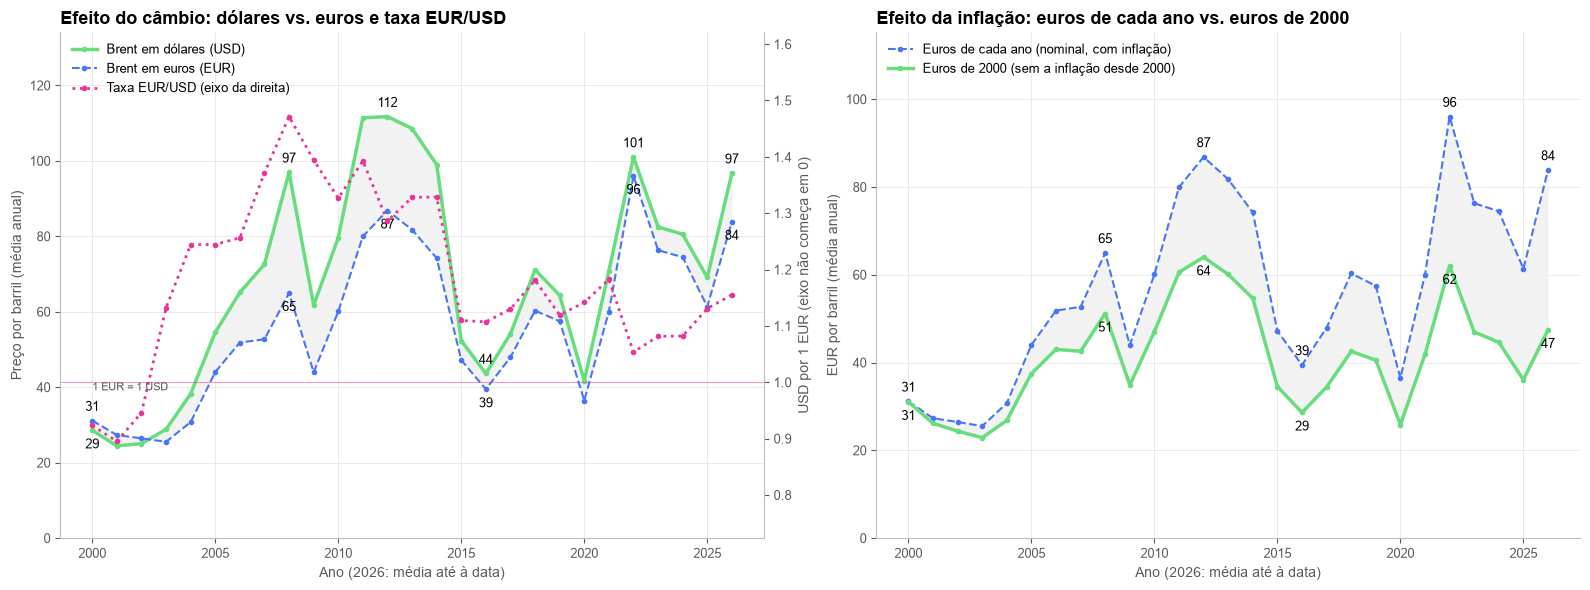

In [28]:
# Brent em médias anuais: efeito do câmbio (preços + taxa EUR/USD num 2.º eixo) e efeito da inflação (euros de cada ano vs. euros de 2000)
py = spark.table("gd_market_yearly").orderBy("year").toPandas()
ANO_BASE = int(py.year.min())                                       # 2000

# Preço em euros de 2000: cada mês * IHPC médio de 2000 / IHPC do mês; depois média anual
ihpc_base = pm.loc[pm.month_date.dt.year == ANO_BASE, "hicp"].mean()
eur_base = (pm.assign(year=pm.month_date.dt.year, v=pm.brent_eur_avg * ihpc_base / pm.hicp)
              .groupby("year").v.mean().rename("brent_eur_base"))
py = py.merge(eur_base, left_on="year", right_index=True)

fig, (ax_c, ax_i) = plt.subplots(1, 2, figsize=(16, 6))
c_usd, c_eur, c_cambio = cores_por_ordem("Brent USD", "Brent EUR", "EUR/USD")   # o Brent em euros fica azul nos dois painéis

# Esquerda: câmbio. Preço em dólares e em euros (eixo da esquerda) e taxa EUR/USD (eixo da direita), os dois eixos a partir de 0
ANOS_ROTULO = [2000, 2008, 2012, 2016, 2022, 2026]
ax_c.fill_between(py.year, py.brent_usd_avg, py.brent_eur_avg, color=NOVA_CINZA_FUNDO, lw=0)
ax_c.plot(py.year, py.brent_usd_avg, color=c_usd, lw=2.5, marker="o", ms=3, label="Brent em dólares (USD)")
ax_c.plot(py.year, py.brent_eur_avg, color=c_eur, ls="--", lw=1.5, marker="o", ms=3, label="Brent em euros (EUR)")
for ano in ANOS_ROTULO:                              # valor de cada linha: o mais alto por cima, o mais baixo por baixo
    r = py[py.year == ano].iloc[0]
    for v in (r.brent_usd_avg, r.brent_eur_avg):
        ax_c.annotate(f"{v:.0f}", (ano, v), xytext=(0, 7 if v == max(r.brent_usd_avg, r.brent_eur_avg) else -13),
                      textcoords="offset points", ha="center", fontsize=9, color=NOVA_TEXTO)
topo = py.brent_usd_avg.max() * 1.2
ax_c.set_ylim(0, topo)
ax_c.set_ylabel("Preço por barril (média anual)")
ax_c.set_title("Efeito do câmbio: dólares vs. euros e taxa EUR/USD")

ax_t = ax_c.twinx()                                  # eixo da direita: taxa de câmbio
ax_t.spines["right"].set_visible(True)
ax_t.grid(False)
ax_t.plot(py.year, py.eurusd_avg, color=c_cambio, ls=":", lw=2, marker="o", ms=3, label="Taxa EUR/USD (eixo da direita)")
ax_t.axhline(1, color=c_cambio, lw=0.8, alpha=0.5)
ax_t.text(py.year.min(), 1.0, "1 EUR = 1 USD", fontsize=8, color=NOVA_CINZA_TEXTO, va="top")
# Eixo da direita alinhado com o da esquerda em dois pontos, para comparar a forma das curvas:
# a taxa de 2000 fica à altura do preço de 2000 (média de USD e EUR) e a taxa máxima à altura do preço máximo em USD.
# Por isso este eixo não começa em 0
p0, p1 = (py.brent_usd_avg.iloc[0] + py.brent_eur_avg.iloc[0]) / 2, py.brent_usd_avg.max()
r0, r1 = py.eurusd_avg.iloc[0], py.eurusd_avg.max()
b = (p1 - p0) / (r1 - r0)                            # preço por cada unidade da taxa
ax_t.set_ylim(r0 - p0 / b, r0 + (topo - p0) / b)
ax_t.set_ylabel("USD por 1 EUR (eixo não começa em 0)")
linhas = ax_c.get_legend_handles_labels(), ax_t.get_legend_handles_labels()
ax_c.legend(linhas[0][0] + linhas[1][0], linhas[0][1] + linhas[1][1], loc="upper left")

# Direita: inflação. Nominal (euros de cada ano) vs. real (euros de 2000)
c_real, c_eur = cores_por_ordem("Brent EUR 2000", "Brent EUR")
ax_i.fill_between(py.year, py.brent_eur_avg, py.brent_eur_base, color=NOVA_CINZA_FUNDO, lw=0)
ax_i.plot(py.year, py.brent_eur_avg, color=c_eur, ls="--", lw=1.5, marker="o", ms=3, label="Euros de cada ano (nominal, com inflação)")
ax_i.plot(py.year, py.brent_eur_base, color=c_real, lw=2.5, marker="o", ms=3, label=f"Euros de {ANO_BASE} (sem a inflação desde {ANO_BASE})")
for ano in ANOS_ROTULO:                              # valor de cada linha: o mais alto por cima, o mais baixo por baixo
    r = py[py.year == ano].iloc[0]
    for v in (r.brent_eur_avg, r.brent_eur_base):
        ax_i.annotate(f"{v:.0f}", (ano, v), xytext=(0, 7 if v == max(r.brent_eur_avg, r.brent_eur_base) else -13),
                      textcoords="offset points", ha="center", fontsize=9, color=NOVA_TEXTO)
ax_i.set_ylim(0, py.brent_eur_avg.max() * 1.2)
ax_i.set_ylabel("EUR por barril (média anual)")
ax_i.set_title(f"Efeito da inflação: euros de cada ano vs. euros de {ANO_BASE}")
ax_i.legend(loc="upper left")
for ax in (ax_c, ax_i):
    ax.set_xlabel("Ano (2026: média até à data)")
plt.tight_layout(); plt.show()

**Resposta à pergunta 1**

*Como ler:* os dois gráficos mostram médias anuais do preço do Brent (2026 é a média até à data). No da esquerda, a linha verde é o Brent em dólares, o preço cotado no mercado mundial, e a azul tracejada é o Brent em euros, o que paga um comprador português. A linha rosa pontilhada é a taxa EUR/USD, em dólares por 1 euro, e lê-se no eixo da direita. Esse eixo não começa em 0, porque o alinhámos em dois pontos: a taxa de 2000 fica à altura do preço de 2000 e a taxa máxima à altura do preço máximo.

No gráfico da direita, a linha azul tracejada é a mesma do gráfico da esquerda (euros de cada ano) e a verde é esse preço em euros de 2000, ou seja, sem a inflação portuguesa desde 2000 (IHPC). Em cada gráfico, a área cinzenta é a diferença entre as duas linhas de preço.

**Conclusões:**
- O Brent passou de 28,6 USD em 2000 para 97 USD em 2026, com picos em 2008, 2012 e 2022 e quedas em 2015-16 e em 2020.
- Quando o euro valoriza, o Brent fica mais barato em euros. Em 2008 o euro valia 1,47 USD e o Brent custou 97 USD, mas só 65 €. Desde 2000 multiplicou por 3,4 em dólares e por 2,7 em euros.
- Em euros de 2000, o pico mais alto é o de 2012 (64 €), seguido de 2022 (62 €) e de 2008 (51 €).

**Resposta:** Sim. Descontada a inflação, o Brent de 2026 custa 47 € de 2000, cerca de **1,5 vezes** os 31 € de 2000. Em dólares custa 3,4 vezes mais.

<a id="s6-2"></a>
### 6.2 Bolsa portuguesa e Brent

**Pergunta 2:** A bolsa portuguesa desce quando o Brent sobe?

A dispersão compara, mês a mês, a variação do Brent (EUR) com a das ações portuguesas. À esquerda está o mercado (índice OCDE, 2000-2026); à direita, cada setor das empresas analisadas, na mesma escala. A tabela dá a correlação do mercado por frequência e período. As correlações usam sempre retornos, nunca níveis, pela razão dada na introdução.

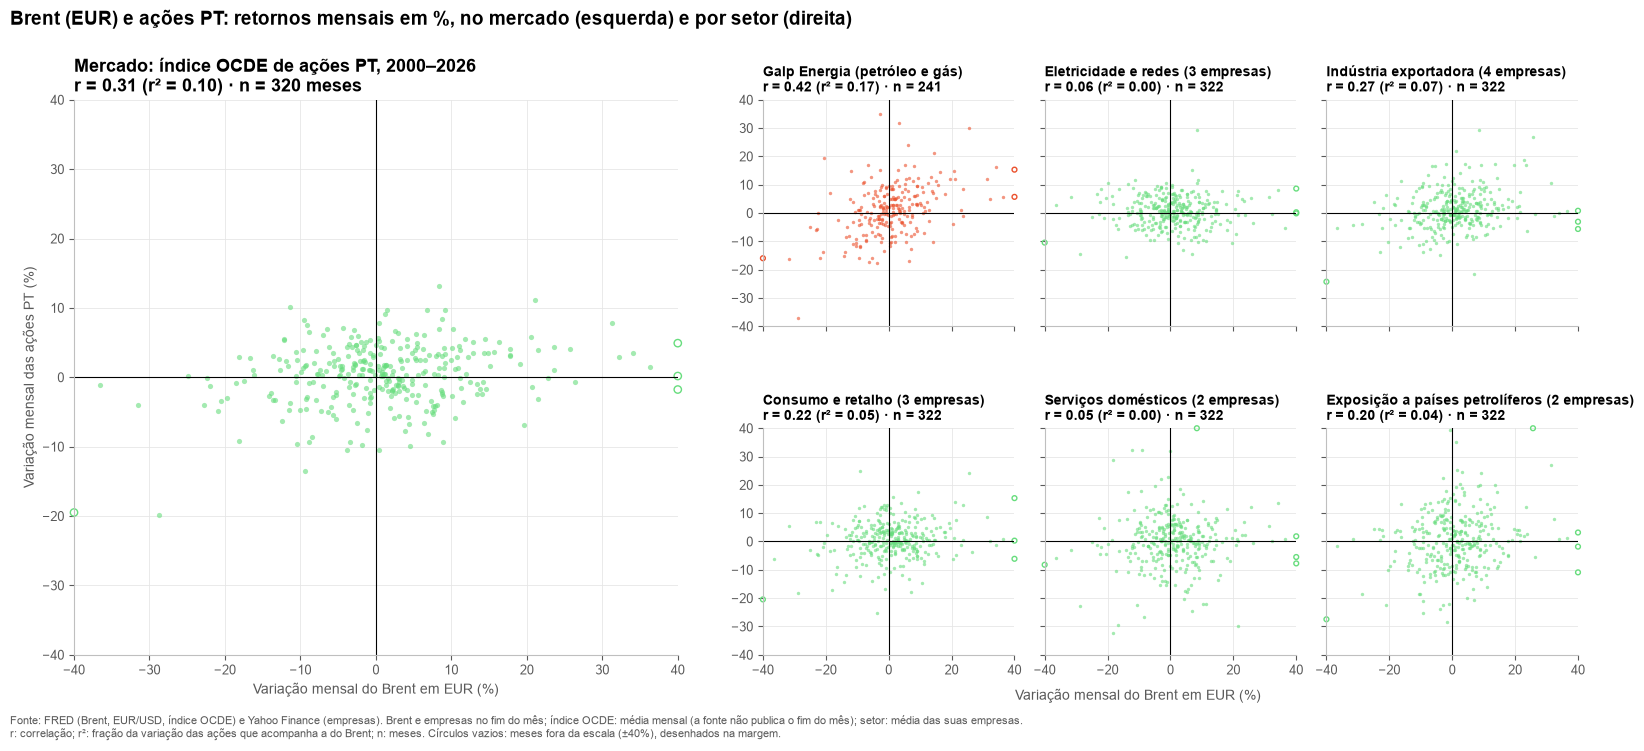

In [29]:
# Retornos mensais vs. Brent (EUR): mercado (índice OCDE, 2000-2026) à esquerda e um painel por setor à direita, na mesma escala
mm = pm.dropna(subset=["ret_brent_eur_m", "ret_pt_shares_m"])
# Setor: média (pesos iguais) do retorno mensal das empresas do setor, em cada mês; o cabaz fica de fora
sec = (eqm[eqm.sector != "Cabaz sem Galp"].dropna(subset=["ret_m_stat", "ret_brent_eur_m"])
         .groupby(["sector", "month_date"])
         .agg(ret=("ret_m_stat", "mean"), brent=("ret_brent_eur_m", "first")).reset_index())
n_emp = eqm[eqm.sector != "Cabaz sem Galp"].groupby("sector").instrument_id.nunique()
SETORES = [s for s in SECTOR_ORDER if s in n_emp.index]

# Escala comum, cortada nos meses extremos (sobretudo 2020) para a nuvem não ficar espremida:
# os pontos fora da escala são desenhados na margem, com um círculo vazio
LIM_X, LIM_Y = 40, 40
fig = plt.figure(figsize=(16, 7.5))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.35], left=0.05, right=0.99, bottom=0.12, top=0.86, wspace=0.12)
gs_set = gs[0, 1].subgridspec(2, 3, wspace=0.12, hspace=0.45)

def r_txt(r):
    # r e r² (fração da variação das ações que acompanha a do Brent)
    return f"r = {r:.2f} (r² = {r * r:.2f})"

def dispersao(ax, x, y, titulo, ms, cor=HIERARQUIA[0]):
    """Dispersão de retornos em %, sem reta (a relação é fraca), com os zeros marcados e a mesma escala em todos os painéis."""
    x, y = (np.exp(x) - 1) * 100, (np.exp(y) - 1) * 100   # retornos logarítmicos para variação simples em %
    fora = (x.abs() > LIM_X) | (y.abs() > LIM_Y)
    ax.scatter(x[~fora], y[~fora], s=ms, alpha=.6, color=cor, lw=0)
    ax.scatter(x[fora].clip(-LIM_X, LIM_X), y[fora].clip(-LIM_Y, LIM_Y), s=ms * 2, facecolors="none",
               edgecolors=cor, lw=1, clip_on=False)
    ax.axhline(0, color=NOVA_PRETO, lw=.8); ax.axvline(0, color=NOVA_PRETO, lw=.8)
    ax.set_xlim(-LIM_X, LIM_X); ax.set_ylim(-LIM_Y, LIM_Y)
    ax.set_title(titulo, fontsize=10 if ms < 14 else 13)

ax_m = fig.add_subplot(gs[0, 0])
dispersao(ax_m, mm.ret_brent_eur_m, mm.ret_pt_shares_m,
          f"Mercado: índice OCDE de ações PT, 2000–2026\n{r_txt(mm.ret_brent_eur_m.corr(mm.ret_pt_shares_m))} · n = {len(mm)} meses", 14)
ax_m.set_xlabel("Variação mensal do Brent em EUR (%)"); ax_m.set_ylabel("Variação mensal das ações PT (%)")

for j, setor in enumerate(SETORES):
    d = sec[sec.sector == setor]
    ax = fig.add_subplot(gs_set[j // 3, j % 3])
    # Um setor com uma só empresa leva o nome dela (o petróleo e gás é só a Galp)
    nome = (f"{eqm.loc[eqm.sector == setor, 'name'].iloc[0]} ({setor.lower()})" if n_emp[setor] == 1
            else f"{setor} ({n_emp[setor]} empresas)")
    dispersao(ax, d.brent, d.ret, f"{nome}\n{r_txt(d.brent.corr(d.ret))} · n = {len(d)}", 6,
              cor=C_GALP if setor == "Petróleo e gás" else HIERARQUIA[0])
    if j % 3: ax.tick_params(labelleft=False)
    if j // 3 == 0: ax.tick_params(labelbottom=False)
fig.text(0.715, 0.06, "Variação mensal do Brent em EUR (%)", ha="center", fontsize=10, color=NOVA_CINZA_TEXTO)
fig.suptitle("Brent (EUR) e ações PT: retornos mensais em %, no mercado (esquerda) e por setor (direita)",
             x=0.01, ha="left")
fig.text(0.01, 0.005, "Fonte: FRED (Brent, EUR/USD, índice OCDE) e Yahoo Finance (empresas). Brent e empresas no fim do mês; índice OCDE: "
         f"média mensal (a fonte não publica o fim do mês); setor: média das suas empresas.\nr: correlação; r²: fração da variação das ações "
         f"que acompanha a do Brent; n: meses. Círculos vazios: meses fora da escala (±{LIM_X}%), "
         "desenhados na margem.", fontsize=8, color=NOVA_CINZA_TEXTO, ha="left", va="bottom")
plt.show()


In [30]:
dly = spark.table("gd_market_daily").filter("year >= 2013 AND psi_traded")
mth = spark.table("gd_market_monthly")
corr_df = (dly.agg(F.corr("ret_psi", "ret_brent_eur").alias("c")).select(F.lit("Diária 2013–2026: PSI vs Brent EUR").alias("medida"), "c")
    .union(dly.agg(F.corr("ret_psi", "ret_eurusd")).select(F.lit("Diária 2013–2026: PSI vs EUR/USD"), "*"))
    .union(mth.agg(F.corr("ret_pt_shares_m", "ret_brent_eur_m")).select(F.lit("Mensal 2000–2026: ações PT (OCDE) vs Brent EUR"), "*"))
    .union(mth.agg(F.corr("ret_psi_m", "ret_brent_eur_m")).select(F.lit("Mensal 2013–2026: PSI vs Brent EUR"), "*"))
    .union(mth.agg(F.corr("pt_shares_idx", "brent_eur_avg")).select(F.lit("Níveis mensais 2000–2026: ações PT vs Brent EUR"), "*"))
    .withColumn("correlacao", F.round("c", 3)).drop("c"))
tabela_nova(corr_df.toPandas().rename(columns={"medida": "Medida", "correlacao": "Correlação (r)"}))

Medida,Correlação (r)
Diária 2013–2026: PSI vs Brent EUR,0.21
Diária 2013–2026: PSI vs EUR/USD,0.04
Mensal 2000–2026: ações PT (OCDE) vs Brent EUR,0.31
Mensal 2013–2026: PSI vs Brent EUR,0.32
Níveis mensais 2000–2026: ações PT vs Brent EUR,0.51


**Resposta à pergunta 2**

*Como ler:* cada ponto é um mês, com a variação do Brent em euros na horizontal e a das ações na vertical. Se a nuvem está inclinada para cima, as ações sobem com o Brent; se é redonda, não há relação. O mercado e os setores estão a verde e a Galp a laranja, todos na mesma escala. Os círculos vazios são meses extremos (sobretudo 2020), desenhados na margem. O r é a correlação (de -1 a +1) e o r² é a fração da variação das ações que acompanha a do Brent. O índice OCDE é uma média mensal, porque a fonte não publica o fim do mês.

**Conclusões:**
- No mercado a relação é positiva e fraca: r = 0,31 nos retornos mensais (r² = 0,10, ou seja, 10%) e 0,21 nos retornos diários do PSI. O câmbio quase não conta (0,04). Nos níveis a correlação sobe para 0,51, mas vem de tendências longas comuns.
- A Galp é a que mais acompanha o Brent (r = 0,42). A indústria exportadora, o consumo e as empresas expostas a países petrolíferos ficam entre 0,20 e 0,27, e a eletricidade e os serviços domésticos não se relacionam com o Brent (cerca de 0,05).

**Resposta:** Não. A bolsa portuguesa move-se em média no mesmo sentido do Brent, com uma correlação mensal de **0,31**. Nenhum setor desce quando o Brent sobe.

<a id="s6-3"></a>
### 6.3 Ligação ao longo do tempo

**Pergunta 3:** A ligação entre a bolsa portuguesa e o Brent muda ao longo do tempo?

O primeiro gráfico mostra a correlação móvel do mercado com o Brent (EUR), com as crises sombreadas. Não há PSI diário antes de 2013, por isso o gráfico junta duas medidas. A primeira é a correlação diária do PSI nos 12 meses anteriores (desde 2014). A segunda é a correlação mensal do cabaz das 14 empresas sem a Galp nos 36 meses anteriores (desde 2003). O mapa de calor repete a correlação de 36 meses para cada empresa, no fim de cada ano.

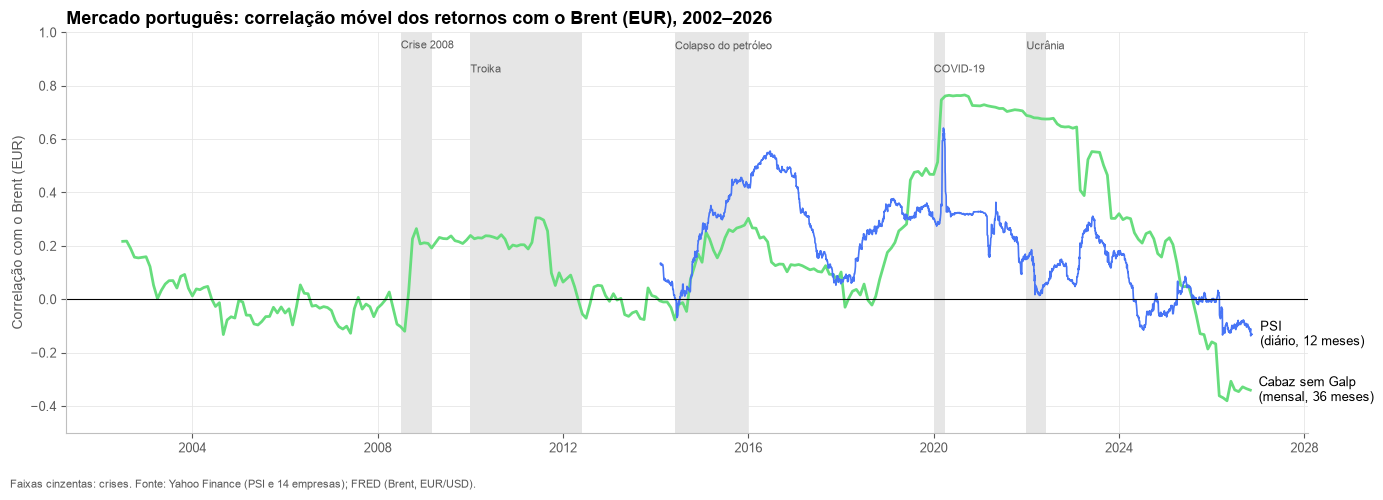

2013-05 a 2026-11 (163 meses), correlação com o Brent: cabaz 0.34, PSI 0.32; cabaz com PSI 0.90


In [31]:
# Correlação móvel com o Brent (EUR): PSI (retornos diários, 1 ano) e cabaz sem Galp (retornos mensais, 36 meses)
cab = eqm[eqm.instrument_id == "PT_EX_GALP"].sort_values("month_date").dropna(subset=["corr_36m_brent"])
psi = pdl.dropna(subset=["corr_1y_psi_brent"])
c_cab, c_psi = cores_por_ordem("Cabaz sem Galp", "PSI")
fig, ax = plt.subplots(figsize=(14, 5))
sombrear_crises(ax)
ax.plot(cab.month_date, cab.corr_36m_brent, color=c_cab, lw=2)
ax.plot(psi.date, psi.corr_1y_psi_brent, color=c_psi, lw=1.2)
ax.axhline(0, color=NOVA_PRETO, lw=.8)
ax.set_ylim(-0.5, 1.0)                                   # espaço em cima para os nomes das crises
rotular_fim(ax, [(cab.month_date.iloc[-1], cab.corr_36m_brent.iloc[-1], "Cabaz sem Galp\n(mensal, 36 meses)"),
                 (psi.date.iloc[-1], psi.corr_1y_psi_brent.iloc[-1], "PSI\n(diário, 12 meses)")], folga=0.12)
ax.set_ylabel("Correlação com o Brent (EUR)")
ax.set_title(f"Mercado português: correlação móvel dos retornos com o Brent (EUR), {cab.month_date.min():%Y}–{cab.month_date.max():%Y}")
finalizar(fig, "Faixas cinzentas: crises. Fonte: Yahoo Finance (PSI e 14 empresas); FRED (Brent, EUR/USD).")

# Teste dos pesos iguais: cabaz (pesos iguais) vs PSI (ponderado pela capitalização), retornos mensais de fim de mês desde 2013
ret_psi_eom = np.log(pm.set_index("month_date").psi_eom).diff().rename("ret_psi")
cmp = (eqm[eqm.instrument_id == "PT_EX_GALP"].set_index("month_date")[["ret_m_stat", "ret_brent_eur_m"]]
         .join(ret_psi_eom, how="inner").dropna())
print(f"{cmp.index.min():%Y-%m} a {cmp.index.max():%Y-%m} ({len(cmp)} meses), correlação com o Brent: "
      f"cabaz {cmp.ret_m_stat.corr(cmp.ret_brent_eur_m):.2f}, PSI {cmp.ret_psi.corr(cmp.ret_brent_eur_m):.2f}; "
      f"cabaz com PSI {cmp.ret_m_stat.corr(cmp.ret_psi):.2f}")

*Como ler o gráfico de linhas:* cada linha é a correlação com o Brent (EUR) numa janela móvel e as faixas cinzentas são as crises. A verde é o cabaz das 14 empresas sem a Galp (retornos mensais, 36 meses) e a azul é o PSI (retornos diários, 12 meses). Acima de zero, o mercado e o Brent movem-se no mesmo sentido.

**Conclusões:**
- O cabaz fica perto de zero até 2008 e sobe para entre 0,2 e 0,3 depois da crise de 2008 e na troika. Chega a 0,73 no fim de 2020 (COVID-19) e cai para -0,34 na subida do Brent de 2026.
- O PSI é positivo entre 2014 e 2023, com picos de 0,56 em 2016 e 0,64 em 2020 (COVID-19), e fica perto de zero ou negativo em 2024-2026 (-0,13 em novembro de 2026).
- O cabaz pesa as empresas por igual e o PSI pela capitalização. Desde 2013-05 (163 meses), a correlação mensal com o Brent é 0,34 no cabaz e 0,32 no PSI e os dois retornos têm correlação de 0,90, por isso o cabaz representa bem o PSI.

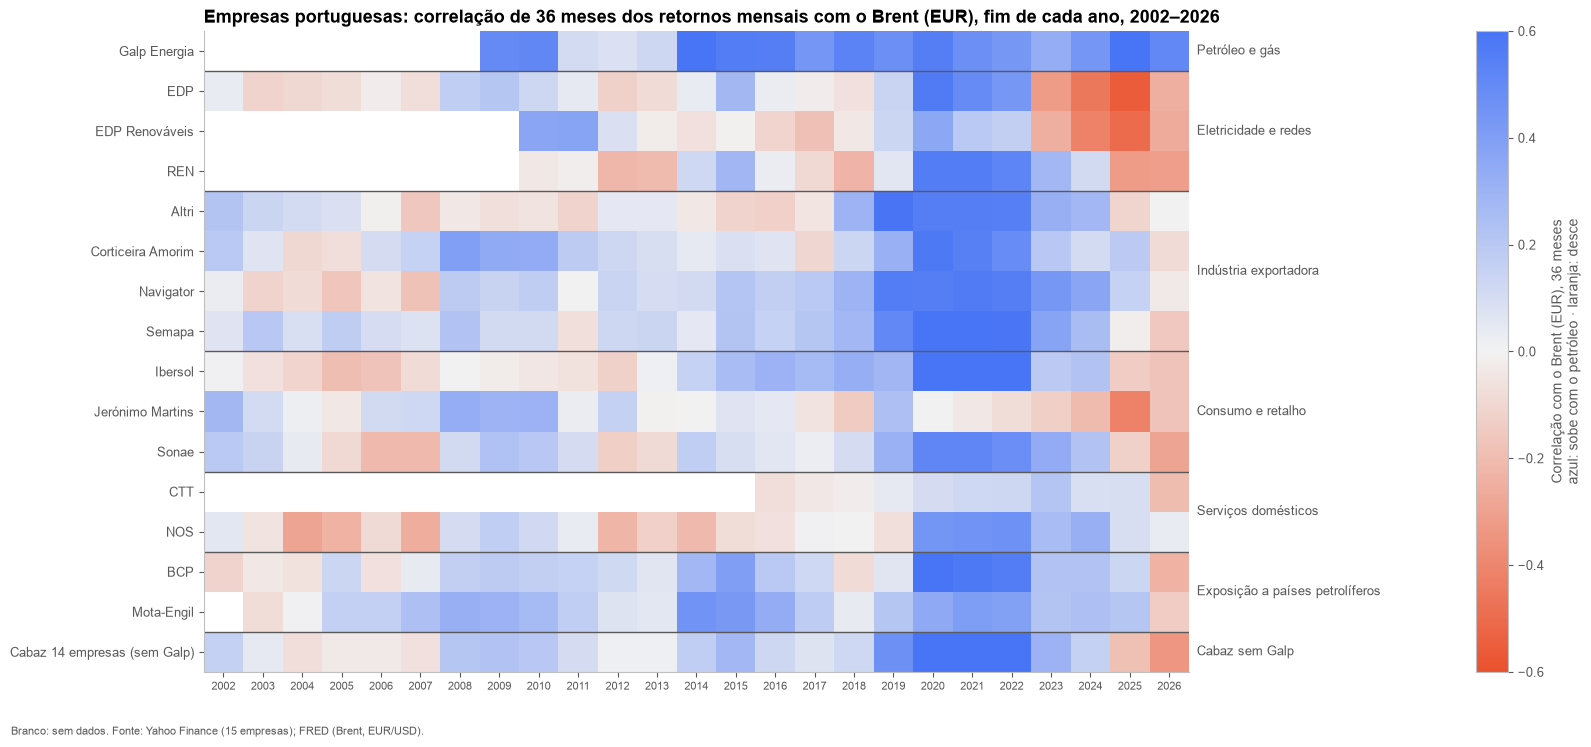

In [32]:
# Mapa de calor: correlação móvel de 36 meses (retornos mensais) de cada empresa com o Brent, no fim de cada ano
names = (eqm[["instrument_id", "name", "sector"]].drop_duplicates()
         .assign(_s=lambda d: d.sector.map(SECTOR_ORDER.index)).sort_values(["_s", "name"]).reset_index(drop=True))
fim_ano = eqm.sort_values("month_date").groupby(["instrument_id", "year"]).tail(1)   # dezembro (ou último mês disponível)
hm = fim_ano.pivot(index="instrument_id", columns="year", values="corr_36m_brent").reindex(names.instrument_id)
hm = hm.loc[:, hm.notna().any()]

fig, ax = plt.subplots(figsize=(16, 7.5))
im = ax.imshow(hm.values, cmap=CMAP_DIVERGENTE, vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_yticks(range(len(names))); ax.set_yticklabels(names.name)
ax.set_xticks(range(len(hm.columns))); ax.set_xticklabels(hm.columns, rotation=0, fontsize=8)
ax.grid(False)
for i in range(1, len(names)):                      # separadores e nomes dos setores
    if names.sector[i] != names.sector[i - 1]:
        ax.axhline(i - 0.5, color=NOVA_CINZA_TEXTO, lw=1)
for sec, grp in names.groupby("sector", sort=False):
    ax.text(len(hm.columns) - 0.3, grp.index.to_series().mean(), sec, va="center", fontsize=9, color=NOVA_CINZA_TEXTO)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.22)
cb.set_label("Correlação com o Brent (EUR), 36 meses\nazul: sobe com o petróleo · laranja: desce")
ax.set_title(f"Empresas portuguesas: correlação de 36 meses dos retornos mensais com o Brent (EUR), fim de cada ano, "
             f"{hm.columns.min()}–{hm.columns.max()}")
finalizar(fig, "Branco: sem dados. Fonte: Yahoo Finance (15 empresas); FRED (Brent, EUR/USD).")

**Resposta à pergunta 3**

*Como ler o mapa de calor:* cada linha é uma empresa (agrupadas por setor) e cada coluna é o fim de um ano, com a correlação dos 36 meses anteriores. A azul a ação sobe com o Brent, a laranja desce quando o Brent sobe, e a branco não há dados.

**Conclusões:**
- No fim de 2020, o ano da COVID-19, a maioria das empresas passa de 0,5, porque caem e recuperam com o Brent.
- No fim de 2025 aparece laranja na EDP (-0,56), na EDP Renováveis (-0,50) e na Jerónimo Martins (-0,41).

**Resposta:** Sim. A ligação é mais forte nas crises de procura: no fim de 2020 (COVID-19), a correlação do cabaz chega a **0,73**. Inverte-se na subida do Brent de 2026, em que cai para -0,34.

<a id="s6-4"></a>
### 6.4 Efeito por empresa

**Pergunta 4:** O Brent penaliza as empresas portuguesas, com exceção da Galp?

Para cada empresa calculamos três efeitos com os retornos mensais. Os três leem-se como a variação média da ação, em %, num mês em que o Brent (EUR) sobe 10%:
- **A, efeito total** (2000-2026);
- **B, sem a bolsa portuguesa**: descontada a média das outras empresas nesse mês (2000-2026);
- **C, sem a bolsa europeia**: descontado o Euro Stoxx 50 nesse mês (2007-2026, desde que há dados).

O gráfico compara os três efeitos e a tabela dá o veredicto face à hipótese (Galp +, restantes -).

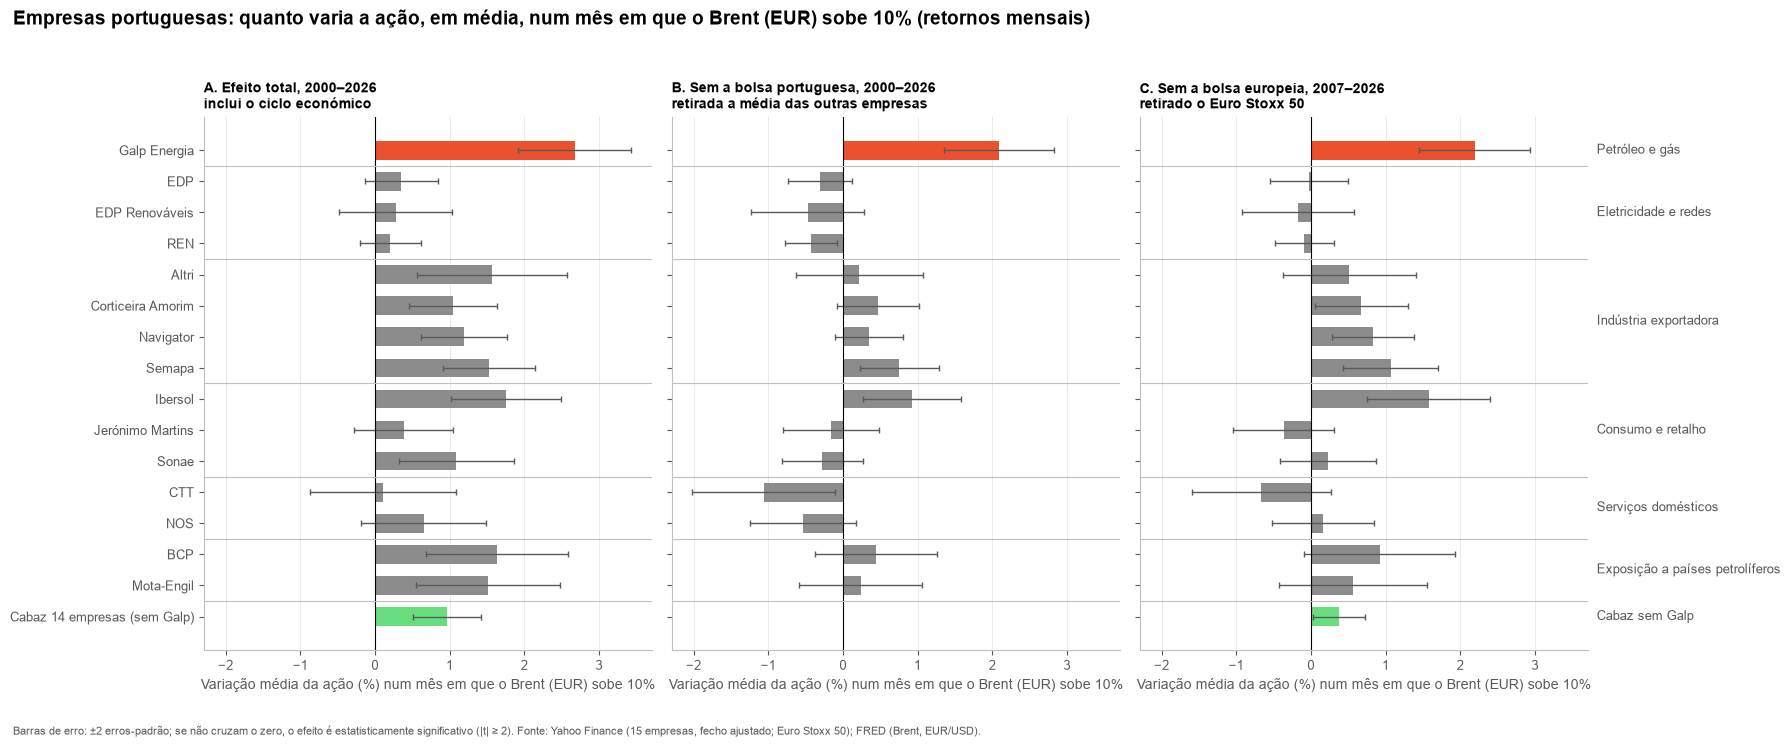

In [33]:
# Efeito do petróleo por empresa: total, sem a bolsa portuguesa e sem a bolsa europeia
sens = spark.table("gd_oil_sensitivity").filter("periodo = 'Total 2000-2026'").toPandas()
sens = (sens.assign(_s=sens.sector.map(SECTOR_ORDER.index))
            .sort_values(["_s", "name"], ascending=[False, False]).reset_index(drop=True))
pos = range(len(sens))
# Cor só para a protagonista (Galp) e a comparação (cabaz sem Galp); as restantes empresas a cinzento, agrupadas por setor
c_galp, c_cab = cores_por_ordem("GALP.LS", "PT_EX_GALP")
cores = [c_galp if i == "GALP.LS" else c_cab if i == "PT_EX_GALP" else NOVA_CINZA for i in sens.instrument_id]
fig, axes = plt.subplots(1, 3, figsize=(18, 7.5), sharey=True, sharex=True)   # mesma escala nos três painéis
for ax, b, se, title in [(axes[0], "beta", "se_beta", "A. Efeito total, 2000–2026\ninclui o ciclo económico"),
                         (axes[1], "beta_sem_mercado", "se_beta_sem_mercado",
                          "B. Sem a bolsa portuguesa, 2000–2026\nretirada a média das outras empresas"),
                         (axes[2], "beta_sem_europa", "se_beta_sem_europa",
                          "C. Sem a bolsa europeia, 2007–2026\nretirado o Euro Stoxx 50")]:
    ok = sens[b].notna()
    ax.barh([p for p, o in zip(pos, ok) if o], sens.loc[ok, b] * 10, xerr=2 * sens.loc[ok, se] * 10, height=0.6,
            color=[c for c, o in zip(cores, ok) if o], error_kw={"ecolor": NOVA_CINZA_TEXTO, "elinewidth": 1, "capsize": 2})
    ax.axvline(0, color=NOVA_PRETO, lw=.8)
    for i in range(1, len(sens)):                    # separadores entre setores
        if sens.sector[i] != sens.sector[i - 1]:
            ax.axhline(i - 0.5, color=NOVA_CINZA_EIXO, lw=0.8)
    ax.set_title(title, fontsize=10); ax.grid(axis="y", visible=False)
    ax.set_xlabel("Variação média da ação (%) num mês em que o Brent (EUR) sobe 10%")
axes[0].set_yticks(list(pos)); axes[0].set_yticklabels(sens.name)
for sec, grp in sens.groupby("sector", sort=False):   # nomes dos setores à direita do último painel
    axes[2].text(1.02, grp.index.to_series().mean(), sec, transform=axes[2].get_yaxis_transform(),
                 va="center", fontsize=9, color=NOVA_CINZA_TEXTO)
fig.suptitle("Empresas portuguesas: quanto varia a ação, em média, num mês em que o Brent (EUR) sobe 10% (retornos mensais)",
             x=0.01, ha="left")
finalizar(fig, "Barras de erro: ±2 erros-padrão; se não cruzam o zero, o efeito é estatisticamente significativo (|t| ≥ 2). "
               "Fonte: Yahoo Finance (15 empresas, fecho ajustado; Euro Stoxx 50); FRED (Brent, EUR/USD).", topo=0.95)


*Como ler o gráfico:* cada barra é a variação média da ação, em %, num mês em que o Brent (EUR) sobe 10%, e os três painéis têm a mesma escala. O A mistura o custo do Brent com o ciclo económico, que faz subir o Brent e as bolsas ao mesmo tempo. O B retira o que vem da bolsa portuguesa e o C o que vem da bolsa europeia. A Galp está a laranja, o cabaz das 14 empresas sem a Galp a verde (não tem B, porque o cabaz já é a bolsa portuguesa) e as restantes a cinzento, agrupadas por setor. A linha preta é o intervalo de 2 erros-padrão para cada lado: se cruza o zero, o efeito não é significativo.

**Conclusões:**
- A (total): todas as empresas sobem com o Brent, 8 delas de forma significativa. A Galp sobe +2,7%.
- B (sem a bolsa portuguesa): a Galp continua positiva (+2,1%) e 7 empresas passam a negativo, mas só a REN e os CTT de forma significativa.
- C (sem a bolsa europeia): a Galp sobe +2,2%. Nenhuma empresa desce de forma significativa e 4 continuam a subir (Corticeira Amorim, Navigator, Semapa e Ibersol).

In [34]:
# Veredicto por empresa face à hipótese (Galp +, restantes -), na mesma ordem do gráfico; tabela formatada para a apresentação
ver = spark.sql("""
    SELECT name AS Empresa, oil_hypothesis AS `Sinal esperado`,
           ROUND(beta * 10, 1) AS `A. Efeito total (%)`, veredicto AS `Veredicto A`,
           ROUND(beta_sem_mercado * 10, 1) AS `B. Sem bolsa PT (%)`, veredicto_sem_mercado AS `Veredicto B`,
           ROUND(beta_sem_europa * 10, 1) AS `C. Sem bolsa europeia (%)`, veredicto_sem_europa AS `Veredicto C`,
           instrument_id, sector
    FROM gd_oil_sensitivity
    WHERE periodo = 'Total 2000-2026'
""").toPandas()
ver = (ver.assign(_s=ver.sector.map(SECTOR_ORDER.index)).sort_values(["_s", "Empresa"])
          .drop(columns=["_s", "instrument_id", "sector"]).reset_index(drop=True))
CURTO = {"Sem efeito significativo": "Sem efeito", "Dados insuficientes": "Sem dados"}
for col in ("Veredicto A", "Veredicto B", "Veredicto C"):
    ver[col] = ver[col].map(lambda v: CURTO.get(v, v) if isinstance(v, str) else "-")

def cor_veredicto(v):
    # Confirma a verde claro e a negrito; Contraria a negrito; Sem efeito a cinzento
    return {"Confirma": "background-color: #D9F6DF; font-weight: bold;", "Contraria": "font-weight: bold;"}.get(
        v, f"color: {NOVA_CINZA_TEXTO};")

tabela_nova(ver, casas=1).map(cor_veredicto, subset=["Veredicto A", "Veredicto B", "Veredicto C"]).format(
    {"A. Efeito total (%)": "{:+.1f}", "B. Sem bolsa PT (%)": "{:+.1f}", "C. Sem bolsa europeia (%)": "{:+.1f}"}, na_rep="-")


Empresa,Sinal esperado,A. Efeito total (%),Veredicto A,B. Sem bolsa PT (%),Veredicto B,C. Sem bolsa europeia (%),Veredicto C
Galp Energia,+,+2.7,Confirma,+2.1,Confirma,+2.2,Confirma
EDP,-,+0.4,Sem efeito,-0.3,Sem efeito,+0.0,Sem efeito
EDP Renováveis,-,+0.3,Sem efeito,-0.5,Sem efeito,-0.2,Sem efeito
REN,-,+0.2,Sem efeito,-0.4,Confirma,-0.1,Sem efeito
Altri,-,+1.6,Contraria,+0.2,Sem efeito,+0.5,Sem efeito
Corticeira Amorim,-,+1.0,Contraria,+0.5,Sem efeito,+0.7,Contraria
Navigator,-,+1.2,Contraria,+0.3,Sem efeito,+0.8,Contraria
Semapa,-,+1.5,Contraria,+0.8,Contraria,+1.1,Contraria
Ibersol,-,+1.8,Contraria,+0.9,Contraria,+1.6,Contraria
Jerónimo Martins,-,+0.4,Sem efeito,-0.2,Sem efeito,-0.4,Sem efeito


**Resposta à pergunta 4**

*Como ler a tabela:* há uma linha por empresa, pela ordem do gráfico, com o valor e o veredicto de cada efeito (A, B e C) face ao sinal esperado. *Confirma* (a verde) quer dizer que o efeito é significativo e tem o sinal da hipótese. *Contraria* (a negrito) é significativo, mas com o sinal oposto. *Sem efeito* (a cinzento) não é significativo.

**Conclusões:**
- A (total): só a Galp confirma; 8 empresas contrariam a hipótese (sobem com o Brent).
- B (sem a bolsa portuguesa): a Galp, a REN e os CTT confirmam; a Ibersol e a Semapa contrariam.
- C (sem a bolsa europeia): só a Galp confirma; 4 empresas e o cabaz contrariam.

**Resposta:** Não. Só a **REN** e os **CTT** descem com o Brent (-0,4% e -1,1% por cada +10%), e só quando se desconta a bolsa portuguesa. Descontada a bolsa europeia, nenhuma empresa desce de forma significativa. A explicação mais provável é o ciclo económico, que faz subir o Brent e as ações ao mesmo tempo.

<a id="s6-5"></a>
### 6.5 Galp e restantes empresas

**Pergunta 5:** A Galp reage ao Brent de forma diferente das restantes empresas?

Comparamos a Galp com o cabaz das outras 14 empresas. O primeiro gráfico mostra a correlação com o Brent ao longo do tempo. O segundo mostra quanto cada um varia, em média, consoante o Brent sobe ou desce no mês.

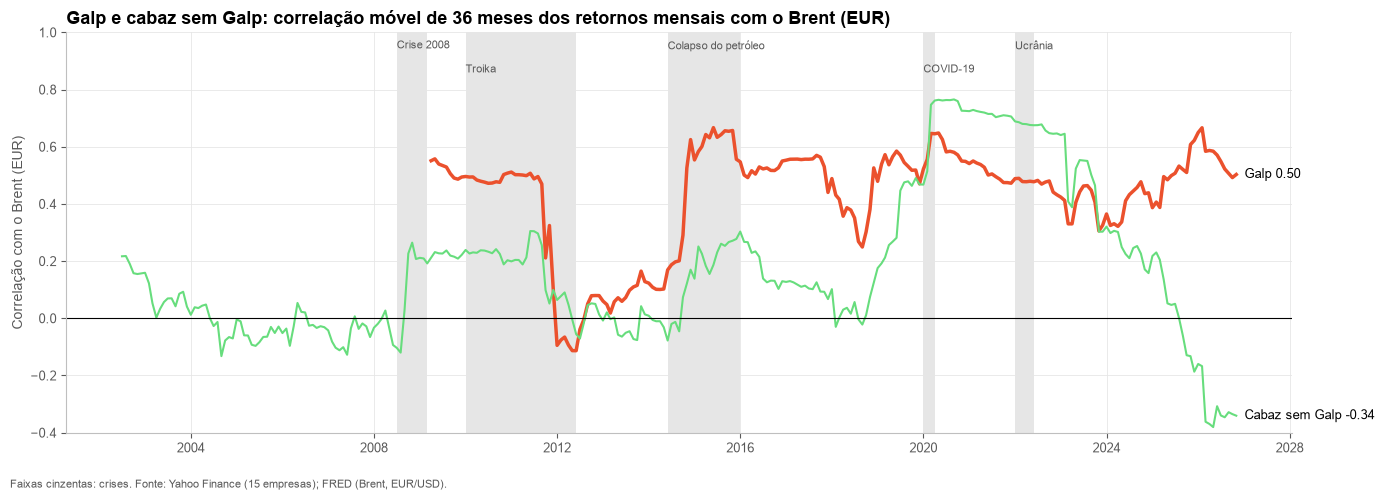

In [35]:
# Correlação móvel de 36 meses: Galp vs. cabaz das outras 14 empresas, com as crises assinaladas
fig, ax = plt.subplots(figsize=(14, 5))
sombrear_crises(ax)
rotulos = []
for iid, cor, label in zip(["GALP.LS", "PT_EX_GALP"], cores_por_ordem("GALP.LS", "PT_EX_GALP"), ["Galp", "Cabaz sem Galp"]):
    d = eqm[eqm.instrument_id == iid].sort_values("month_date")
    ax.plot(d.month_date, d.corr_36m_brent, color=cor, lw=2.5 if iid == "GALP.LS" else 1.5)
    last = d.dropna(subset=["corr_36m_brent"]).iloc[-1]
    rotulos.append((last.month_date, last.corr_36m_brent, f"{label} {last.corr_36m_brent:.2f}"))
ax.axhline(0, color=NOVA_PRETO, lw=.8)
ax.set_ylim(-0.4, 1.0)                                   # espaço em cima para os nomes das crises
rotular_fim(ax, rotulos)
ax.set_ylabel("Correlação com o Brent (EUR)")
ax.set_title("Galp e cabaz sem Galp: correlação móvel de 36 meses dos retornos mensais com o Brent (EUR)")
finalizar(fig, "Faixas cinzentas: crises. Fonte: Yahoo Finance (15 empresas); FRED (Brent, EUR/USD).")

*Como ler o gráfico de correlação:* as linhas são a correlação dos retornos mensais com o Brent (EUR) nos 36 meses anteriores, e as faixas cinzentas são as crises. A laranja, mais grossa, é a Galp, que só começa em 2009 (36 meses depois da entrada em bolsa). A verde é o cabaz das outras 14 empresas. Acima de zero, a ação move-se no mesmo sentido do Brent.

**Conclusões:**
- A Galp tem uma ligação forte e estável, acima de 0,3 em 82% dos meses (máximo de 0,67 em 2015). Só caiu para perto de zero entre 2012 e 2014 e fecha em 0,50.
- O cabaz fica acima de 0,3 em só 20% dos meses. Sobe nas crises de procura (0,73 no fim de 2020) e cai para -0,34 na subida do Brent de 2026, enquanto a Galp continua positiva.

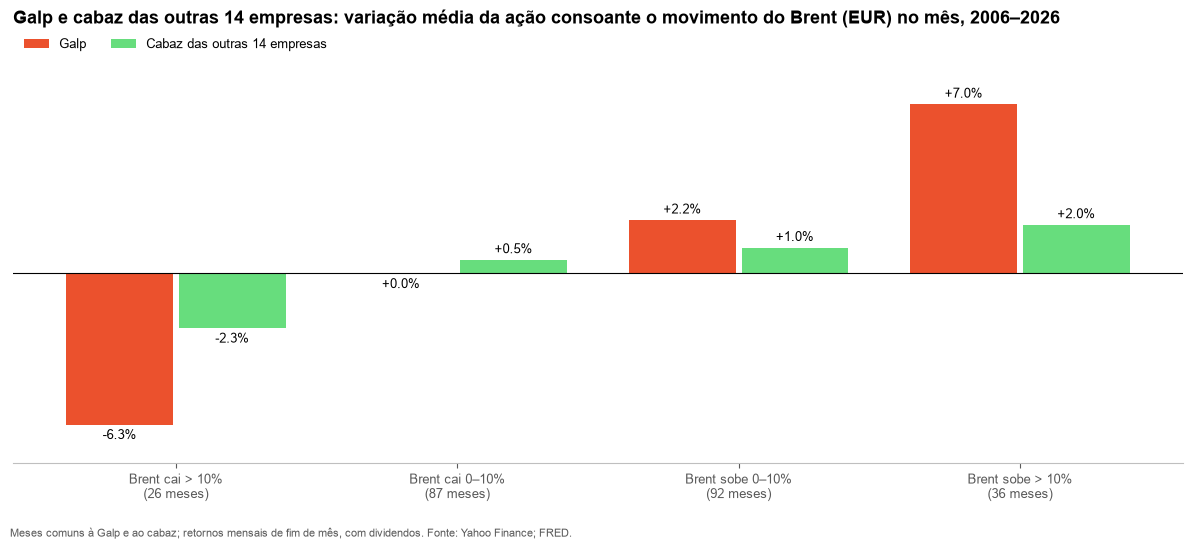

In [36]:
# Reação ao Brent: variação média mensal da Galp e do cabaz consoante o movimento do Brent (EUR) no mês
g = eqm[eqm.instrument_id == "GALP.LS"].set_index("month_date")
cab = eqm[eqm.instrument_id == "PT_EX_GALP"].set_index("month_date")
r = pd.DataFrame({"brent": g.ret_brent_eur_m, "Galp": g.ret_m_stat, "Cabaz sem Galp": cab.ret_m_stat}).dropna()   # meses comuns
r = np.exp(r) - 1                                        # retornos logarítmicos para variação simples
GRUPOS = ["Brent cai > 10%", "Brent cai 0–10%", "Brent sobe 0–10%", "Brent sobe > 10%"]
r["grupo"] = pd.cut(r.brent, [-np.inf, -0.10, 0, 0.10, np.inf], labels=GRUPOS)
res = r.groupby("grupo", observed=True).agg(Galp=("Galp", "mean"), Cabaz=("Cabaz sem Galp", "mean"), n=("brent", "size")) * [100, 100, 1]

fig, ax = plt.subplots(figsize=(12, 5.5))
pos = np.arange(len(res))
c_galp, c_cab = cores_por_ordem("GALP.LS", "PT_EX_GALP")
for d, col, cor, nome in [(-0.2, "Galp", c_galp, "Galp"), (0.2, "Cabaz", c_cab, "Cabaz das outras 14 empresas")]:
    barras = ax.bar(pos + d, res[col], width=0.38, color=cor, label=nome)
    ax.bar_label(barras, labels=[f"{0 if abs(v) < 0.05 else v:+.1f}%" for v in res[col]], padding=3, fontsize=9)
ax.axhline(0, color=NOVA_PRETO, lw=.8)
ax.set_xticks(pos); ax.set_xticklabels([f"{grp}\n({int(n)} meses)" for grp, n in zip(res.index, res.n)])
ax.grid(visible=False); ax.yaxis.set_visible(False); ax.spines["left"].set_visible(False)   # os rótulos substituem o eixo
ax.set_ylim(min(res[["Galp", "Cabaz"]].min().min() * 1.25, 0), max(res[["Galp", "Cabaz"]].max().max() * 1.25, 0))
ax.set_title(f"Galp e cabaz das outras 14 empresas: variação média da ação consoante o movimento do Brent (EUR) no mês, "
             f"{r.index.min():%Y}–{r.index.max():%Y}", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
finalizar(fig, "Meses comuns à Galp e ao cabaz; retornos mensais de fim de mês, com dividendos. Fonte: Yahoo Finance; FRED.")

**Resposta à pergunta 5**

*Como ler o gráfico de barras:* os meses desde 2006 estão divididos em quatro grupos, consoante a variação do Brent (EUR) no mês. Para cada grupo, as barras dão a variação média da Galp (laranja) e do cabaz das outras 14 empresas (verde) nesses meses, com dividendos. Por baixo de cada grupo está o número de meses.

**Conclusões:**
- Quando o Brent cai mais de 10%, a Galp cai 6,3% e o cabaz 2,3%. Quando sobe mais de 10%, a Galp sobe 7,0% e o cabaz 2,0%.
- Quando o Brent cai até 10%, a Galp fica estável (0,0%) e o cabaz sobe 0,5%.

**Resposta:** Sim. A Galp move-se com o Brent cerca de **três vezes** mais do que o cabaz e tem correlação de 36 meses acima de 0,3 em 82% dos meses. Em 2026 a Galp acompanhou o Brent e o cabaz foi em sentido contrário (-0,34).

<a id="s6-6"></a>
### 6.6 Bolsa e Brent nas crises

**Pergunta 6:** Nas crises de 2008, da COVID-19 e da guerra na Ucrânia, a bolsa portuguesa acompanhou o Brent?

Para cada episódio comparamos a variação do Brent (EUR) com a das ações portuguesas, do início ao fim do episódio. As datas seguem uma regra: o início é o fim do mês antes do choque e o fim é o mês do extremo do Brent (ou das ações, na bolha dot-com e na troika).

Usamos dados mensais para cobrir 2000-2026, porque o PSI diário só existe desde 2013. Além das três crises da pergunta, entram seis episódios com grandes variações do Brent ou da bolsa portuguesa. A tabela dá os valores e o gráfico mostra o padrão.

In [37]:
# Episódios por regra: início = fim do mês antes da janela; fim = mês do extremo da série de referência dentro da janela
# (Brent nos choques do petróleo; índice OCDE de ações PT na bolha dot-com e na troika, em que o Brent quase não mexeu)
crises_df = spark.sql("""
WITH episodios AS (
  SELECT * FROM VALUES
    ('Bolha dot-com',               'Ações PT', 'queda',  DATE'2000-03-01', DATE'2003-06-01'),
    ('Subida do petróleo 2007-08',  'Brent',    'subida', DATE'2007-01-01', DATE'2008-12-01'),
    ('Crise financeira 2008',       'Brent',    'queda',  DATE'2008-06-01', DATE'2009-06-01'),
    ('Crise da dívida (troika)',    'Ações PT', 'queda',  DATE'2010-01-01', DATE'2012-12-01'),
    ('Colapso do petróleo 2014-16', 'Brent',    'queda',  DATE'2014-06-01', DATE'2016-06-01'),
    ('COVID-19',                    'Brent',    'queda',  DATE'2020-01-01', DATE'2020-06-01'),
    ('Recuperação pós-COVID',       'Brent',    'subida', DATE'2020-05-01', DATE'2021-12-01'),
    ('Guerra na Ucrânia',           'Brent',    'subida', DATE'2022-01-01', DATE'2022-12-01'),
    ('2026 até hoje',               'Brent',    'subida', DATE'2026-01-01', DATE'2026-12-01')
  AS t(episodio, referencia, sentido, ini_janela, fim_janela)),
m AS (   -- o índice OCDE sai com atraso: nos últimos meses usa-se o último valor publicado
  SELECT month_date, brent_eur_eom, psi_eom,
         LAST(pt_shares_idx, TRUE) OVER (ORDER BY month_date) AS pt_shares_idx
  FROM gd_market_monthly),
fim AS (
  SELECT e.episodio,
         CASE WHEN e.referencia = 'Brent' AND e.sentido = 'queda' THEN MIN_BY(m.month_date, m.brent_eur_eom)
              WHEN e.referencia = 'Brent'                         THEN MAX_BY(m.month_date, m.brent_eur_eom)
              WHEN e.sentido = 'queda'                            THEN MIN_BY(m.month_date, m.pt_shares_idx)
              ELSE MAX_BY(m.month_date, m.pt_shares_idx) END AS fim
  FROM episodios e JOIN m ON m.month_date BETWEEN e.ini_janela AND e.fim_janela
  GROUP BY e.episodio, e.referencia, e.sentido)
SELECT e.episodio, e.referencia, ADD_MONTHS(e.ini_janela, -1) AS inicio, f.fim,
       CAST(MONTHS_BETWEEN(f.fim, ADD_MONTHS(e.ini_janela, -1)) AS INT) AS meses,
       ROUND((b.brent_eur_eom / a.brent_eur_eom - 1) * 100, 1) AS var_brent_eur_pct,
       ROUND((b.pt_shares_idx / a.pt_shares_idx - 1) * 100, 1) AS var_acoes_pt_pct,
       ROUND((b.psi_eom / a.psi_eom - 1) * 100, 1) AS var_psi_pct
FROM episodios e JOIN fim f ON f.episodio = e.episodio
JOIN m a ON a.month_date = ADD_MONTHS(e.ini_janela, -1)
JOIN m b ON b.month_date = f.fim
ORDER BY inicio
""")
ep_pd = crises_df.toPandas()

# Sensibilidade: início e fim deslocados 1 mês para cada lado (4 combinações); conta os episódios em que o sinal das ações PT muda
nivel = pm.set_index("month_date").pt_shares_idx.ffill()
def var_acoes(ini, fim):
    return nivel.get(fim) / nivel.get(ini) - 1 if ini in nivel.index and fim in nivel.index else np.nan
muda = [r.episodio for r in ep_pd.itertuples()
        if any(np.sign(var_acoes(pd.Timestamp(r.inicio) + pd.DateOffset(months=di), pd.Timestamp(r.fim) + pd.DateOffset(months=df_)))
               != np.sign(r.var_acoes_pt_pct) for di in (-1, 1) for df_ in (-1, 1))]
print("Sensibilidade (início e fim ±1 mês): o sinal das ações PT " +
      ("não muda em nenhum episódio" if not muda else f"muda em {len(muda)} episódio(s): {', '.join(muda)}"))

tabela_nova(ep_pd.drop(columns="referencia")
            .assign(inicio=lambda d: pd.to_datetime(d.inicio).dt.strftime("%Y-%m"),
                    fim=lambda d: pd.to_datetime(d.fim).dt.strftime("%Y-%m"))
            .rename(columns={"episodio": "Episódio", "inicio": "Início", "fim": "Fim", "meses": "Meses",
                             "var_brent_eur_pct": "Brent EUR (%)", "var_acoes_pt_pct": "Ações PT, OCDE (%)", "var_psi_pct": "PSI (%)"}),
            casas=1).format({"Brent EUR (%)": "{:+.1f}", "Ações PT, OCDE (%)": "{:+.1f}", "PSI (%)": "{:+.1f}"}, na_rep="-")


Sensibilidade (início e fim ±1 mês): o sinal das ações PT muda em 2 episódio(s): Subida do petróleo 2007-08, COVID-19


Episódio,Início,Fim,Meses,Brent EUR (%),"Ações PT, OCDE (%)",PSI (%)
Bolha dot-com,2000-02,2002-10,32,-14.2,-53.2,—
Subida do petróleo 2007-08,2006-12,2008-06,18,+96.7,-3.6,—
Crise financeira 2008,2008-05,2008-12,7,-68.7,-43.2,—
Crise da dívida (troika),2009-12,2012-06,30,+36.8,-33.2,—
Colapso do petróleo 2014-16,2014-05,2016-01,20,-61.8,-20.9,-28.8
COVID-19,2019-12,2020-03,3,-77.7,-14.0,-22.0
Recuperação pós-COVID,2020-04,2021-10,18,+334.4,+46.4,+33.8
Guerra na Ucrânia,2021-12,2022-05,5,+71.4,+5.4,+12.4
2026 até hoje,2025-12,2026-03,3,+110.4,+10.9,+10.5


*Como ler a tabela:* há uma linha por episódio, por ordem cronológica, com a duração em meses e a variação em %, do início ao fim, do Brent em euros, das ações portuguesas (índice OCDE, média mensal) e do PSI. O PSI só existe desde 2013, por isso tem um traço antes dessa data. O fim de cada episódio é o mês do mínimo (nas quedas) ou do máximo (nas subidas) dentro da janela; em 2026 é o máximo até hoje. Por cima da tabela está o teste com o início e o fim deslocados 1 mês.

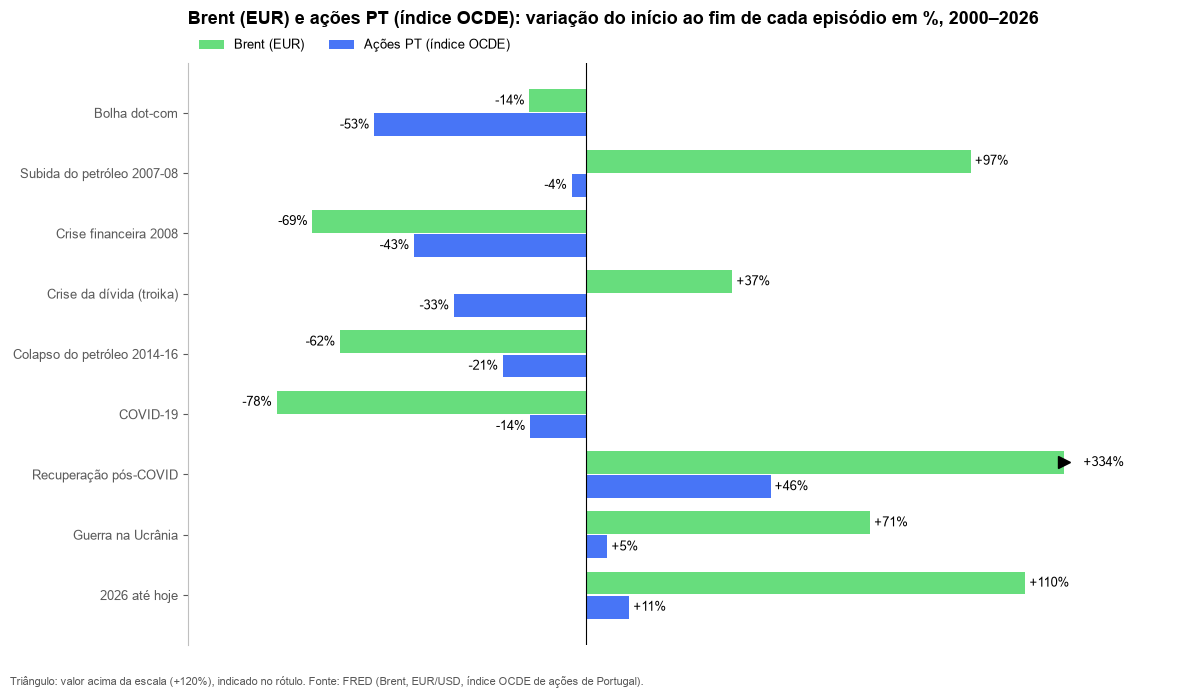

In [38]:
# Barras agrupadas: variação do Brent (EUR) e das ações PT (OCDE) em cada episódio, do mais antigo (em cima) ao mais recente
ep = ep_pd.iloc[::-1].reset_index(drop=True)
pos = np.arange(len(ep))
fig, ax = plt.subplots(figsize=(12, 7))
X_MAX = 120          # escala até +120%: a recuperação pós-COVID esmagaria o resto; leva um marcador de outlier
c_brent, c_acoes = cores_por_ordem("Brent (EUR)", "Ações PT")
for d, col, cor, nome in [(0.2, "var_brent_eur_pct", c_brent, "Brent (EUR)"), (-0.2, "var_acoes_pt_pct", c_acoes, "Ações PT (índice OCDE)")]:
    v = ep[col]
    barras = ax.barh(pos + d, v.clip(upper=X_MAX), height=0.38, color=cor, label=nome)
    ax.bar_label(barras, labels=[f"{x:+.0f}%" if pd.notna(x) and x <= X_MAX else "" for x in v], padding=3, fontsize=9)
    for p_, x in zip(pos, v):
        if x > X_MAX:    # valor acima da escala: triângulo no fim da barra
            ax.plot(X_MAX, p_ + d, marker=">", ms=9, color=NOVA_PRETO, clip_on=False)
            ax.text(X_MAX + 5, p_ + d, f"{x:+.0f}%", va="center", fontsize=9)
ax.set_xlim(-100, X_MAX + 30)
ax.set_yticks(pos); ax.set_yticklabels(ep.episodio)
ax.axvline(0, color=NOVA_PRETO, lw=.8)
ax.grid(visible=False); ax.xaxis.set_visible(False); ax.spines["bottom"].set_visible(False)   # os rótulos substituem o eixo
ax.set_title("Brent (EUR) e ações PT (índice OCDE): variação do início ao fim de cada episódio em %, 2000–2026", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
finalizar(fig, f"Triângulo: valor acima da escala (+{X_MAX}%), indicado no rótulo. Fonte: FRED (Brent, EUR/USD, índice OCDE de ações de Portugal).")


**Resposta à pergunta 6**

*Como ler o gráfico:* são os mesmos episódios da tabela, do mais antigo (em cima) ao mais recente, e cada par de barras é a variação do início ao fim do episódio. A verde é o Brent em euros e a azul as ações portuguesas. Se as duas barras estão do mesmo lado do zero, andaram no mesmo sentido. A escala vai até +120%, por isso a recuperação pós-COVID (+334%) vai até ao limite, com um triângulo e o valor real no rótulo.

**Conclusões:**
- Nas crises de procura (2008 e COVID-19) o Brent e a bolsa caem juntos. Em 2008, o Brent cai 69% e as ações 43%; na COVID-19, 78% e 14%. Na recuperação pós-COVID sobem juntos (+334% e +46%).
- Na guerra na Ucrânia e na subida de 2026, o Brent sobe 71% e 110% e as ações sobem só 5% e 11%.
- Há episódios em que vão em sentidos opostos: na subida do Brent de 2007-08 (+97%), as ações caem 4%, e na crise da dívida (troika) o Brent sobe 37% e as ações caem 33%.
- Com as datas deslocadas 1 mês, o sinal das ações muda na subida de 2007-08 e na COVID-19, que são episódios curtos ou com variações pequenas das ações.

**Resposta:** Em parte. Na crise de 2008 a bolsa acompanha a queda do Brent (-43% contra -69%). Na guerra na Ucrânia sobe muito menos do que o Brent (**+5%** contra +71%). Na COVID-19 a queda das ações (-14%) depende das datas escolhidas.

<a id="s6-7"></a>
### 6.7 Explicar e antecipar o PSI

**Pergunta 7:** O Brent explica os movimentos diários do PSI e permite antecipá-los?

Usamos dois modelos do Spark MLlib, com dados de 2013-2026:
- **Regressão linear (explicar):** que parte do movimento diário do PSI explicam o Brent (EUR) e o câmbio EUR/USD no mesmo dia?
- **Random Forest (antecipar):** com a informação conhecida hoje (retornos passados do PSI e do Brent, médias móveis, volatilidade), o modelo prevê se o PSI sobe amanhã? Treina até 2023 e é testado em 2024-2026, para não misturar o futuro com o passado.

In [39]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator, RegressionEvaluator

ml_base = spark.table("gd_market_daily").filter("year >= 2013 AND psi_traded AND ret_psi IS NOT NULL AND ret_brent_eur IS NOT NULL AND ret_eurusd IS NOT NULL")

lr_df = VectorAssembler(inputCols=["ret_brent_eur", "ret_eurusd"], outputCol="features").transform(ml_base)
# Mesma divisão temporal do Random Forest: treino até 2023, teste em 2024-2026 (R² fora da amostra)
lr_train, lr_test = lr_df.filter("year <= 2023"), lr_df.filter("year >= 2024")
lr_model = LinearRegression(featuresCol="features", labelCol="ret_psi").fit(lr_train)
r2_teste = RegressionEvaluator(labelCol="ret_psi", metricName="r2").evaluate(lr_model.transform(lr_test))
print(f"Regressão linear  ret_psi = {lr_model.intercept:.5f} + {lr_model.coefficients[0]:.4f}·ret_brent_eur + {lr_model.coefficients[1]:.4f}·ret_eurusd")
# Resultado para a apresentação: o que o modelo explica e o efeito de cada variável
tabela_nova(pd.DataFrame({
    "Medida": ["R² no treino (2013–2023): parte da variação diária do PSI explicada", "R² no teste (2024–2026)",
               "PSI no mesmo dia, se o Brent (EUR) sobe 10%", "PSI no mesmo dia, se o EUR/USD sobe 10%", "Dias (treino / teste)"],
    "Valor": [f"{lr_model.summary.r2:.1%}", f"{r2_teste:.1%}", f"{lr_model.coefficients[0] * 10:+.2f}%",
              f"{lr_model.coefficients[1] * 10:+.2f}%", f"{lr_model.summary.numInstances} / {lr_test.count()}"]}))

Regressão linear  ret_psi = 0.00002 + 0.1029·ret_brent_eur + 0.1160·ret_eurusd


Medida,Valor
R² no treino (2013–2023): parte da variação diária do PSI explicada,7.3%
R² no teste (2024–2026),-15.4%
"PSI no mesmo dia, se o Brent (EUR) sobe 10%",+1.03%
"PSI no mesmo dia, se o EUR/USD sobe 10%",+1.16%
Dias (treino / teste),2718 / 733


*Como ler a regressão:* o R² é a parte da variação diária do PSI que o modelo explica. No teste pode ser negativo, o que quer dizer que o modelo erra mais do que prever sempre a média. Os efeitos dizem quanto o PSI se move, em média, no mesmo dia, quando a variável sobe 10%.

**Conclusões:**
- No treino (2013-2023), o Brent e o câmbio explicam 7,3% da variação diária do PSI. Uma subida de 10% do Brent associa-se a +1,03% do PSI no mesmo dia.
- No teste (2024-2026) o R² é -15,4%. A relação de 2013-2023 não se mantém nos últimos anos, o que bate com a correlação negativa de 2024-2026 (ver 6.3).

In [40]:
w = Window.orderBy("date")    # série única: janela global (ver nota na secção 4)
feat = ml_base
# psi_lag1 = retorno de hoje (conhecido no fecho), psi_lag2 = ontem, ... ; o alvo é o retorno de amanhã
feat = feat.withColumn("psi_lag1", F.col("ret_psi")).withColumn("brent_lag1", F.col("ret_brent_eur"))
for k in range(2, 6):
    feat = feat.withColumn(f"psi_lag{k}", F.lag("ret_psi", k - 1).over(w)).withColumn(f"brent_lag{k}", F.lag("ret_brent_eur", k - 1).over(w))
feat = (feat.withColumn("psi_vs_ma50", F.col("psi_close") / F.col("psi_ma50") - 1)
            .withColumn("psi_vs_ma200", F.col("psi_close") / F.col("psi_ma200") - 1)
            .withColumn("brent_vs_ma50", F.col("brent_eur") / F.col("brent_eur_ma50") - 1)
            .withColumn("label", (F.lead("ret_psi", 1).over(w) > 0).cast("double"))
            .dropna())
features = [f"psi_lag{k}" for k in range(1, 6)] + [f"brent_lag{k}" for k in range(1, 6)] + \
           ["ret_eurusd", "psi_vs_ma50", "psi_vs_ma200", "brent_vs_ma50", "vol_1y_psi", "vol_1y_brent", "corr_1y_psi_brent"]
data = VectorAssembler(inputCols=features, outputCol="features").transform(feat)
train, test = data.filter("year <= 2023"), data.filter("year >= 2024")

rf = RandomForestClassifier(featuresCol="features", labelCol="label", numTrees=200, maxDepth=5, seed=42).fit(train)
pred = rf.transform(test)
auc = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC").evaluate(pred)
acc = MulticlassClassificationEvaluator(labelCol="label", metricName="accuracy").evaluate(pred)
baseline = test.agg(F.avg("label")).first()[0]
print(f"Treino: {train.count()} dias | Teste: {test.count()} dias")
imp = sorted(zip(features, rf.featureImportances.toArray()), key=lambda x: -x[1])[:5]
print("Variáveis mais importantes: " + ", ".join(f"{f} ({v:.3f})" for f, v in imp))
# Desfasamentos mensais: correlação com o Brent de 1, 2 e 3 meses antes, em todas as empresas e no cabaz (Gold)
lag = spark.sql("""SELECT MIN(LEAST(corr_lag1, corr_lag2, corr_lag3)) AS mn, MAX(GREATEST(corr_lag1, corr_lag2, corr_lag3)) AS mx
                   FROM gd_oil_sensitivity WHERE periodo = 'Total 2000-2026'""").first()
print(f"Correlação mensal com o Brent de 1, 2 e 3 meses antes (15 empresas e cabaz, 2000–2026): de {lag.mn:.2f} a {lag.mx:.2f}")
# Resultado para a apresentação: o modelo contra a regra ingénua "sobe sempre" (e contra o acaso, AUC = 0,5)
tabela_nova(pd.DataFrame({
    "Medida (teste 2024–2026)": ["Accuracy: dias em que acerta se o PSI sobe ou desce", "AUC: 0,5 = acaso, 1 = perfeito"],
    "Random Forest": [f"{acc:.1%}", f"{auc:.2f}"],
    "Referência": [f"{max(baseline, 1 - baseline):.1%} (regra 'sobe sempre')", "0.50 (acaso)"]}))

Treino: 2521 dias | Teste: 732 dias
Variáveis mais importantes: psi_lag1 (0.121), psi_lag3 (0.072), psi_lag4 (0.067), ret_eurusd (0.067), brent_lag2 (0.067)
Correlação mensal com o Brent de 1, 2 e 3 meses antes (15 empresas e cabaz, 2000–2026): de -0.12 a 0.09


Medida (teste 2024–2026),Random Forest,Referência
Accuracy: dias em que acerta se o PSI sobe ou desce,47.5%,53.6% (regra 'sobe sempre')
"AUC: 0,5 = acaso, 1 = perfeito",0.44,0.50 (acaso)


**Resposta à pergunta 7**

*Como ler o Random Forest:* a accuracy compara-se com a regra ingénua "sobe sempre" e a AUC com o acaso (0,5). Um modelo útil teria de superar as duas.

**Conclusões:**
- O Random Forest acerta em 47,5% dos dias (AUC 0,44), abaixo da regra "sobe sempre" (53,6%) e do acaso.
- A correlação mensal com o Brent de 1, 2 e 3 meses antes vai de -0,12 a 0,09, em todas as empresas e no cabaz (é a linha impressa acima da tabela).

**Resposta:** Não. O Brent explica 7,3% da variação diária do PSI até 2023, mas essa relação não se mantém em 2024-2026 (R² de **-15,4%**). Também não antecipa o dia seguinte: o Random Forest fica abaixo da regra ingénua.

<a id="s7"></a>
## 7. Conclusões

Respostas às 7 perguntas da introdução, em quatro partes: os dados (7.1), a hipótese do grupo (7.2), o processo (7.3) e a tecnologia (7.4).

_Os valores citados são da execução local de 13-11-2026. Se o notebook voltar a correr mais tarde, os últimos meses podem mudar ligeiramente._

| # | Pergunta | Resposta (secção 6) |
|---|---|---|
| 1 | O Brent está hoje mais caro do que em 2000, em dólares, em euros e descontada a inflação? | Sim. Em euros de 2000 custa 1,5 vezes mais (47 € contra 31 €) |
| 2 | A bolsa portuguesa desce quando o Brent sobe? | Não. Move-se no mesmo sentido (correlação mensal de 0,31) |
| 3 | A ligação entre a bolsa portuguesa e o Brent muda ao longo do tempo? | Sim. Chega a 0,73 no fim de 2020 e a -0,34 em 2026 |
| 4 | O Brent penaliza as empresas portuguesas, com exceção da Galp? | Não. Só a REN e os CTT descem, e só sem a bolsa portuguesa |
| 5 | A Galp reage ao Brent de forma diferente das restantes empresas? | Sim. Move-se cerca de três vezes mais do que o cabaz |
| 6 | Nas crises de 2008, da COVID-19 e da guerra na Ucrânia, a bolsa portuguesa acompanhou o Brent? | Em parte. Cai com ele em 2008; sobe muito menos em 2022 |
| 7 | O Brent explica os movimentos diários do PSI e permite antecipá-los? | Não. R² de 7,3% até 2023, negativo em 2024-2026 |

<a id="s7-1"></a>
### 7.1 Sobre os dados

**1.** O Brent foi de 9 a 144 USD em 26 anos. Passou de uma média de 28,6 USD em 2000 para um máximo de 144 USD em julho de 2008, com mínimos de 34 USD no fim de 2008, 26 USD em 2016 e 9 USD na COVID-19 (abril de 2020). Voltou a subir em 2022 (média de 101 USD) e em 2026 (média de 97 USD até agora, máximo de 138 USD); as causas de 2026 ficam fora do âmbito destes dados. Em euros de 2000, o Brent de 2026 custa 47 €, cerca de 1,5 vezes os 31 € de 2000, e o pico real é o de 2012 (64 €).

**2.** Em euros, o choque de 2008 foi menor, porque o euro valorizou entre 2002 e 2008: nesse ano o Brent custou 97 USD, mas só 65 € (1 EUR = 1,47 USD). Por isso comparamos o petróleo com o PSI em euros. O câmbio quase não se relaciona com o PSI diário (correlação de 0,04).

**3.** A relação entre o petróleo e a bolsa portuguesa é positiva e fraca, e muda com o tempo. A correlação dos retornos é 0,31 (mensal, ações PT da OCDE, 2000-2026) e 0,21 (diária, PSI, 2013-2026). A correlação móvel de 1 ano do PSI foi positiva entre 2014 e 2023 e ficou perto de zero ou negativa em 2024-2026: de janeiro a novembro de 2026 o Brent em euros subiu 58% e o PSI 17%.

**4.** O petróleo acompanha o ciclo económico. Nos meses em que o Brent cai mais de 10%, as ações portuguesas descem em média 1,7% e só sobem em 41% dos meses. Nos meses em que o Brent sobe mais de 10%, ganham em média 1,7% e sobem em 65% dos meses. Nas crises de procura caem juntos (2008: Brent -69%, ações -43%; COVID-19: -78% e -14%) e na recuperação pós-COVID sobem juntos (+334% e +46%).

**5.** Há exceções nas subidas do Brent e nas crises internas. Na subida do petróleo de 2007-08 (Brent +97%), as ações caem 4%. Na crise da dívida (troika), o Brent sobe 37% e as ações caem 33%. Nestes episódios o petróleo caro é um custo para a economia, ou dominam os fatores internos. O sinal de 2007-08 muda quando as datas se deslocam 1 mês (ver 6.6).

**6.** O petróleo explica pouco do PSI e não o antecipa. A regressão linear explica 7,3% da variação diária do PSI em 2013-2023 e deixa de funcionar em 2024-2026 (R² de -15,4%). O Random Forest acerta se o PSI sobe amanhã em 47,5% dos dias, abaixo da regra "sobe sempre" (53,6%). É o que se espera de um mercado eficiente, em que a informação pública do passado não dá vantagem para prever o dia seguinte.

<a id="s7-2"></a>
### 7.2 Sobre a hipótese do grupo (análise mensal por empresa)

**Veredicto:** a hipótese confirma-se na **Galp** e não se confirma nas outras 14 empresas. No efeito total, nenhuma delas desce de forma significativa quando o Brent sobe.

**7.** A Galp confirma a hipótese. Tem correlação mensal de 0,42 com o Brent (EUR) e, num mês em que o Brent sobe 10%, sobe em média +2,7% (t = 7,1). O efeito mantém-se quando se desconta a bolsa portuguesa (+2,1%, t = 5,7) ou a europeia (+2,2%, t = 5,9). Nos três subperíodos desde 2008 a correlação fica entre 0,43 e 0,52.

**8.** As outras 14 empresas não confirmam a hipótese no efeito total. Todas têm correlação positiva com o Brent (0,02 a 0,27), nenhuma desce de forma significativa quando o Brent sobe e 8 sobem (*Contraria*). O cabaz sem a Galp sobe em média +1,0% num mês em que o Brent sobe 10% (t = 4,2). A explicação mais provável é o ciclo económico: quando a economia cresce, o petróleo e as ações sobem juntos e o efeito "custo" fica escondido.

**9.** Descontada a bolsa portuguesa, o efeito "custo" aparece em poucas empresas. 7 das 14 passam a negativo: eletricidade e redes (EDP, EDP Renováveis, REN), serviços domésticos (NOS, CTT) e duas do retalho (Jerónimo Martins, Sonae). Só a REN (-0,4% por cada +10% no Brent, t = -2,5) e os CTT (-1,1%, t = -2,2) são significativos. As exportadoras e as empresas com negócio em países petrolíferos (BCP, Mota-Engil) continuam positivas, como previa a leitura por setor, e a Semapa e a Ibersol são positivas e significativas (*Contraria*). Descontada a bolsa europeia, nenhuma empresa desce de forma significativa. O efeito é pequeno: no máximo -1,1% por cada subida de 10% no Brent.

**10.** A relação depende do tipo de choque.
- Nas crises de procura o petróleo e as ações movem-se juntos. No fim de 2020 (COVID-19), a correlação de 36 meses do cabaz sem a Galp chega a 0,73 e 10 das 15 empresas passam de 0,5. As exceções são a Jerónimo Martins e os CTT, perto de zero.
- Em 2025-2026 a relação inverte-se. No fim de 2025 a correlação já é negativa na EDP (-0,56), na EDP Renováveis (-0,50) e na Jerónimo Martins (-0,41). Em novembro de 2026 as outras 14 empresas ficam entre -0,31 e 0,03 e o cabaz em -0,34, enquanto a Galp fica em 0,50.
- Só na subida de 2026 a bolsa se comporta como a hipótese prevê: a Galp acompanha o Brent e as outras empresas não.

**11.** O efeito não demora a aparecer. As correlações com o Brent de 1, 2 e 3 meses antes vão de -0,12 a 0,09, ou seja, o mercado incorpora o preço do petróleo no próprio mês, o que vai no mesmo sentido do modelo de ML (6.7).

**Limitações:** só entram as 15 empresas que estão hoje no PSI (enviesamento de sobrevivência). O "mercado PT" é a média com pesos iguais destas empresas; em 2013-2026 tem correlação de 0,90 com o PSI (ver 6.3). Os CTT, a EDP Renováveis e a REN têm histórico mais curto (155 a 232 meses).

<a id="s7-3"></a>
### 7.3 Sobre o processo
- O processo segue a arquitetura Medallion: Landing (ficheiros em bruto) → Bronze (histórico append-only) → Silver (modelo normalizado) → Gold (tabelas analíticas).
- Fizemos 2 leituras de 22 séries (5 do FRED e 17 do Yahoo): a carga histórica e uma incremental, que começa no watermark com 45 dias de sobreposição. A Bronze acumulou a sobreposição (32 duplicados por série diária) e o `MERGE` da Silver resolveu-os, ficando a versão mais recente de cada registo.
- Apagámos a Silver e reconstruímo-la só a partir da Bronze, com o mesmo número de linhas em cada tabela. Assim é possível corrigir regras de negócio sem voltar à fonte.
- Na qualidade dos dados, removemos os dias sem cotação (500 no Brent) e convertemos os tipos de texto para número e data. Os valores anómalos mas reais (WTI a -36,98 USD em 20-04-2020) ficaram marcados com `dq_flag` em vez de apagados.
- Nas empresas usámos o fecho ajustado a dividendos e operações de capital. Dois meses da Altri (2000 e 2005), com saltos diários acima de 40% mal ajustados na fonte, ficaram fora das estatísticas.
- Cada registo guarda o `_batch_id` e o ficheiro de origem, e a tabela `ctl_ingestion_log` regista todas as leituras.
- Não há PSI diário gratuito antes de 2013, por isso combinámos duas fontes: o índice mensal da OCDE para 2000-2026 e o PSI diário para 2013-2026.

<a id="s7-4"></a>
### 7.4 Sobre a tecnologia
- Com o Apache Spark usámos a mesma API, em Python e SQL, para ler CSV e JSON aninhado (`explode`/`posexplode`), calcular funções de janela (forward-fill, retornos, médias móveis, correlação móvel) e treinar os modelos de ML (MLlib). As regressões por empresa e período também são feitas em Spark, só com agregações (variâncias e covariâncias), sem ciclos em Python. O volume é pequeno (~7 mil dias e ~94 mil cotações diárias das 15 empresas). Não testámos com mais dados, mas as agregações por empresa não dependem do número de empresas.
- No Delta Lake usámos o `MERGE` para os upserts da Silver, o `DESCRIBE HISTORY` e o `VERSION AS OF` para ver as versões da Gold (*time travel*) e o `OPTIMIZE`/`ZORDER` para otimizar a leitura da Gold.
- O Databricks Free Edition chegou para o projeto (Unity Catalog, Volumes, SQL, dashboards), com três limitações. O acesso à internet é restrito, por isso criámos ficheiros de fallback com o mesmo formato da API. O compute serverless não permite `cache()` e a escala de compute é reduzida.
- Os próximos passos seriam:
  - agendar o pipeline como *Job* diário (hoje as duas leituras correm numa só execução);
  - usar *Auto Loader* ou *Lakeflow Declarative Pipelines* na ingestão;
  - acrescentar taxas de juro, o preço do gás natural e as empresas que saíram da bolsa (enviesamento de sobrevivência);
  - modelar a volatilidade em vez da direção do mercado (o Random Forest não supera o acaso).